# CP1 · B4 — So sánh thuật toán phát hiện stay

Notebook độc lập, không cần chạy lại NB06–NB08. Chọn kernel **Python (GeoLife)** rồi **Run All**.
Tổng hợp selection chạy nền bằng **10 tiến trình theo user**; dữ liệu thật và xác nhận cuối đang tắt.

- 5 detector × 4 radius (50/100/150/200 m) × 2 dwell (10/20 phút) = **40 tổ hợp chung**.
- ST-DBSCAN khảo sát riêng 9 bộ eps_time/MinPts tại 100 m/10 phút, tái dùng 1 bộ gốc: **48 tổ hợp duy nhất**.
- Cùng observations/cases và quy tắc chấm. Mỗi cấu hình có plot so đủ 5 detector; không gộp F1 mọi kịch bản.
- Giữ nguyên baseline, cleaning vote20, generator và corpus B2. Chưa suy accuracy GeoLife hoặc Home/Office.

Protocol: `reports/cp1/detector_protocol.md`. Các ngưỡng được khóa trước khi chạy, không sửa sau khi xem kết quả.


## 1. Cấu hình chạy song song

Đặt sẵn `WORKERS=10`, `RESUME=True`. Run All sẽ khởi động hoặc nhận diện job nền đang chạy,
không chạy trùng. Giữ nguyên các checkpoint đã hoàn tất; chỉ user đang dở phải tính lại.
Mỗi tiến trình xử lý một user với đủ 48 cấu hình; tối đa 10 user cùng lúc.

Job chạy nền độc lập với kernel notebook. Chạy cell **3a — Theo dõi trực tiếp** để xem bảng tự cập nhật mỗi 3 giây.
Nếu chưa completed, các cell bảng/plot phía sau sẽ chờ, không chấm một phần như kết quả đầy đủ.
Khi completed, Run All tái dùng kết quả rồi dựng bảng/plot. Không cần chạy lại NB06–NB08.

**Dừng job nền:** nút Interrupt của notebook không dừng tiến trình nền. Khi cần, chạy
`parallel.request_stop(OUT)` trong một cell; cả nhóm tiến trình sẽ thoát an toàn và giữ checkpoint đã xong.
Để tiếp tục, chạy lại mục 3 với `RESUME=True`.

Sau khi đọc tổng hợp, bật `RUN_REAL=True` và `RUN_DECIDE=True` để xử lý dữ liệu thật tuần tự
và xét điều kiện. Giữ `RUN_FINAL=False` cho đến khi có một winner khóa; giữ baseline thì không chạy final.


In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'src/geolife_inference').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/geolife_inference').is_dir(), 'Mở notebook từ thư mục dự án hoặc notebooks'
sys.path.insert(0, str(ROOT / 'src'))

RUN_REGISTER = True
RUN_SYNTHETIC = True
RUN_REAL = False
RUN_SUMMARIZE = True
RUN_PLOTS = True
RUN_DECIDE = False
RUN_FINAL = False
RESUME = True
WORKERS = 10
OUT = ROOT / 'artifacts/benchmark/b4/run_v1'


In [ ]:
import pandas as pd
from IPython.display import display, Image
from geolife_inference import benchmark_jobs as jobs
from geolife_inference import benchmark_parallel as parallel
from geolife_inference import benchmark_parallel_scaled as scaled_parallel
from geolife_inference import benchmark_decisions as decisions
from geolife_inference import benchmark_plots as plots
from geolife_inference.benchmark_synthetic import file_hash

pd.set_option('display.max_columns', 30)

def stage(name, action):
    """Chỉ tái dùng completed có hash khớp; incomplete cần RESUME cho job hỗ trợ."""
    jobs.validate_lock(ROOT, OUT)
    directory = OUT / name
    audit_path = directory / 'audit.json'
    if audit_path.exists():
        audit = jobs.readj(audit_path)
        if audit.get('status') == 'completed':
            for key in ['output_hashes', 'files']:
                for path, expected in audit.get(key, {}).items():
                    assert file_hash(directory / path) == expected, f'Output đổi: {path}'
            if 'winner_sha256' in audit:
                assert file_hash(directory / 'winner.json') == audit['winner_sha256']
                winner = jobs.readj(directory / 'winner.json')
                assert file_hash(directory / 'gates.csv') == winner['gates_sha256']
            print(f'{name}: tái dùng completed, hashes khớp')
            return audit
    return action()

def show_budget():
    used = jobs.ledger(ROOT, OUT)
    print(f'Compute tích lũy: {used/3600:.3f}/24 giờ; còn {(86400-used)/3600:.3f} giờ')
    print('Ledger gồm khoản dự trữ lịch sử 3.600 giây từ B2, không phải toàn bộ là runtime đã đo.')


## 2. Khóa phụ lục B4 trước chạy detector

Khóa hashes code, bản chụp phần CP1 của PLAN/protocol, B2/B3 audits, profiles, baseline và nhãn phương tiện.
Sau khóa, không sửa code trong cùng namespace. Thay semantics cần phiên bản mới, không ghi đè kết quả cũ.


In [ ]:
if RUN_REGISTER:
    lock = jobs.register(ROOT, OUT)
else:
    lock = jobs.validate_lock(ROOT, OUT)
print('B4 lock:', lock['lock_hash'])
print('Chế độ B2:', lock['mode'])
display(pd.DataFrame(lock['main_configs']))
show_budget()


## 3. Tổng hợp selection — 48 cấu hình

Đọc corpus B2 đã khóa; không sinh lại dữ liệu. Detector chỉ nhận observations, không nhận truth/latent path/nhãn phương tiện.
Chấm từng case bằng cùng matching; giữ cả truth mất hết observations. Log sau mỗi user.
Medoid chính xác có chi phí O(n²) theo độ dài ứng viên: chưa có runtime full grid để hứa thời gian hoàn tất.

Giới hạn: tổng compute tích lũy 24 giờ, detector compute mỗi cấu hình 12 giờ qua các stage/attempts,
RAM working set ≤ min(8 GiB, nửa RAM khả dụng đầu attempt). Chạm ngưỡng thì dừng và ghi incomplete, không âm thầm giảm grid.

Bổ sung thực thi 2026-11-05: chia tối đa 10 user chạy song song bằng process riêng.
Thuật toán/truth/grid/matching không đổi; checkpoint v1 được giữ nguyên. Phụ lục execution có hash
riêng, không thay lock v1. Nâng lên 10 theo yêu cầu 2026-11-05, có scaling policy/hash riêng; engine gốc giữ nguyên.
RAM budget áp dụng cho tổng coordinator + các worker; 24 giờ vẫn tính
wall time tích lũy, còn 12 giờ/cấu hình cộng detector time của mọi worker/attempt.
Timing tổng hợp lẫn serial/parallel chỉ mô tả; gate chi phí (d) vẫn dùng lượt real tuần tự.


In [ ]:
if RUN_SYNTHETIC:
    display(scaled_parallel.launch(ROOT, OUT, workers=WORKERS, resume=RESUME))
    snapshot = parallel.status(OUT)
    if snapshot['status'] == 'running':
        snapshot.pop('error', None)  # Ignore the previous attempt's interrupt while running.
    display(snapshot)
    log = OUT / 'parallel_resume.log'
    if log.exists():
        print('\n'.join(log.read_text(encoding='utf-8', errors='replace').splitlines()[-12:]))
    show_budget()
else:
    print('Tổng hợp đang tắt.')


## 3a. Theo dõi trực tiếp — tự cập nhật mỗi 3 giây

**Chạy riêng cell dưới đây để xem job đang chạy**, không cần Run All hay khởi động lại job.
Cell tự tìm thư mục dự án, chỉ đọc trạng thái. Hiển thị số user xong, các user đang xử lý,
thời gian từng user, CPU và RAM của từng tiến trình; phát hiện cả trường hợp tiến trình đã thoát.

Dấu `[*]` ở cell này nghĩa là bảng đang tự cập nhật. **Bấm Interrupt chỉ tắt bảng theo dõi,
job nền vẫn tiếp tục**. Muốn dừng job thật, dùng `parallel.request_stop(OUT)` như hướng dẫn mục 1.
Khi job hoàn tất hoặc dừng, bảng cũng dừng cập nhật.

Khi có audit dữ liệu thật, bảng tự chuyển sang theo dõi real với đủ 182 user.


In [ ]:
from pathlib import Path
import ctypes
from ctypes import wintypes
import html
import json
import os
import sys
import time
from datetime import datetime
from IPython.display import HTML, display

MONITOR_ROOT = Path.cwd().resolve()
if not (MONITOR_ROOT / 'src/geolife_inference').is_dir():
    MONITOR_ROOT = MONITOR_ROOT.parent
MONITOR_OUT = MONITOR_ROOT / 'artifacts/benchmark/b4/run_v1'
sys.path.insert(0, str(MONITOR_ROOT / 'src'))
from geolife_inference.benchmark_parallel import _process_ws

LIVE_MONITOR = True
REFRESH_SECONDS = 3

if os.name == 'nt':
    _monitor_kernel = ctypes.WinDLL('kernel32', use_last_error=True)
    _monitor_kernel.OpenProcess.argtypes = [wintypes.DWORD, wintypes.BOOL, wintypes.DWORD]
    _monitor_kernel.OpenProcess.restype = wintypes.HANDLE
    _monitor_kernel.CloseHandle.argtypes = [wintypes.HANDLE]
    _monitor_kernel.GetExitCodeProcess.argtypes = [wintypes.HANDLE, ctypes.POINTER(wintypes.DWORD)]
    _monitor_kernel.GetProcessTimes.argtypes = [wintypes.HANDLE] + [ctypes.POINTER(wintypes.FILETIME)] * 4

def monitor_process(pid):
    if not pid:
        return {'alive': False, 'cpu': 0., 'ram': 0.}
    if os.name == 'nt':
        handle = _monitor_kernel.OpenProcess(0x1000, False, int(pid))
        if not handle:
            return {'alive': False, 'cpu': 0., 'ram': 0.}
        try:
            exit_code = wintypes.DWORD()
            alive = bool(_monitor_kernel.GetExitCodeProcess(handle, ctypes.byref(exit_code))) and exit_code.value == 259
            stamps = [wintypes.FILETIME() for _ in range(4)]
            ok = _monitor_kernel.GetProcessTimes(handle, *(ctypes.byref(v) for v in stamps))
            cpu = sum((v.dwHighDateTime << 32) + v.dwLowDateTime for v in stamps[2:]) / 1e7 if ok else 0.
        finally:
            _monitor_kernel.CloseHandle(handle)
        return {'alive': alive, 'cpu': cpu, 'ram': _process_ws(pid) / 1024**2 if alive else 0.}
    path = Path(f'/proc/{pid}/stat')
    if not path.exists():
        return {'alive': False, 'cpu': 0., 'ram': 0.}
    fields = path.read_text().rsplit(')', 1)[1].split()
    return {'alive': fields[0] != 'Z', 'cpu': (int(fields[11]) + int(fields[12])) / os.sysconf('SC_CLK_TCK'),
            'ram': _process_ws(pid) / 1024**2}

def monitor_duration(seconds):
    seconds = max(0, int(seconds)); hours, rest = divmod(seconds, 3600); minutes, seconds = divmod(rest, 60)
    return f'{hours} giờ {minutes:02d} phút' if hours else f'{minutes} phút {seconds:02d} giây'

def watch_b4(refresh_seconds=3, max_updates=None):
    phase = 'real' if (MONITOR_OUT / 'real/audit.json').exists() else 'synthetic_selection'
    path = MONITOR_OUT / phase / 'audit.json'
    prep = json.loads((MONITOR_ROOT / 'artifacts/benchmark/b2/prepared_v1/protocol.json').read_text(encoding='utf-8'))
    total = (len(json.loads((MONITOR_ROOT / 'artifacts/preprocessing/audit.json').read_text(encoding='utf-8'))['expected_users'])
             if phase == 'real' else sum(v == 'selection' for v in prep['split'].values()))
    view = display(HTML('<p>Đang đọc tiến độ B4…</p>'), display_id=True)
    previous = {}; updates = 0
    try:
        while True:
            now = time.time()
            try:
                audit = json.loads(path.read_text(encoding='utf-8'))
            except (FileNotFoundError, json.JSONDecodeError):
                view.update(HTML('<p>Chưa đọc được trạng thái; sẽ kiểm tra lại…</p>'))
                time.sleep(refresh_seconds); continue
            phase = audit['status']; age = now - path.stat().st_mtime
            processes = {pid: monitor_process(pid) for pid in audit.get('worker_pids', [])}
            coordinator = monitor_process(audit.get('coordinator_pid'))
            running = phase == 'running' and coordinator['alive']
            if phase == 'completed':
                label, color = 'Đã hoàn tất', '#15803d'
            elif phase != 'running':
                label, color = 'Đã dừng — checkpoint được giữ', '#b45309'
            elif not coordinator['alive']:
                label, color = 'Tiến trình đã thoát — log chưa đóng', '#b91c1c'
            elif age > 10:
                label, color = 'Tiến trình còn mở — đang chờ cập nhật log', '#b45309'
            else:
                label, color = 'Đang chạy', '#15803d'
            done = len(audit['completed_users']); started = audit.get('active_user_started_epoch', {})
            users = ''.join(f'<tr><td><b>{html.escape(u)}</b></td><td>{monitor_duration(now - started[u]) if u in started else "Đang xử lý"}</td></tr>'
                            for u in audit.get('active_users', [])) or '<tr><td colspan="2">Không có user đang xử lý</td></tr>'
            worker_rows = []
            for index, (pid, process) in enumerate(processes.items(), 1):
                old = previous.get(pid)
                activity = ('Đã thoát' if not process['alive'] else 'Đang đo CPU…' if old is None else
                            'Đang tính toán' if process['cpu'] > old + .001 else 'Đang chờ / đọc dữ liệu')
                worker_rows.append(f'<tr><td>Tiến trình {index}</td><td>{activity}</td><td>{process["ram"]:.0f} MiB</td></tr>')
                previous[pid] = process['cpu']
            error = f'<p>{html.escape(audit.get("error", ""))}</p>' if phase != 'running' else ''
            stamp = datetime.fromtimestamp(now).astimezone().strftime('%H:%M:%S')
            body = f"""<div style="font-family:system-ui;line-height:1.6;max-width:850px">
<h3 style="color:{color};margin-bottom:8px">● {label} · {'Dữ liệu thật' if phase == 'real' else 'Tổng hợp'}</h3>
<strong>{done}/{total} user hoàn tất</strong> · {sum(v['alive'] for v in processes.values())}/{audit.get('workers', 3)} tiến trình đang mở
<progress value="{done}" max="{total}" style="display:block;width:100%;height:18px;margin:10px 0"></progress>
<table style="width:100%;text-align:left"><thead><tr><th>User đang chạy</th><th>Thời gian xử lý</th></tr></thead><tbody>{users}</tbody></table>
<table style="width:100%;text-align:left;margin-top:14px"><thead><tr><th>Worker</th><th>Hoạt động CPU từ lần cập nhật trước</th><th>RAM hiện tại</th></tr></thead><tbody>{''.join(worker_rows)}</tbody></table>
<p>Cập nhật lúc <b>{stamp}</b> · Log cách đây {max(0, int(age))} giây · Compute tích lũy {audit.get('compute_used_after_seconds', 0) / 3600:.2f}/24 giờ</p>
<p style="font-size:12px;opacity:.8">Tự cập nhật mỗi {refresh_seconds} giây. CPU có thể chờ trong lúc đọc/ghi dữ liệu. Dừng cell chỉ tắt bảng theo dõi.</p>{error}</div>"""
            view.update(HTML(body)); updates += 1
            if not running or (max_updates is not None and updates >= max_updates):
                break
            time.sleep(refresh_seconds)
    except KeyboardInterrupt:
        print('Đã tắt bảng theo dõi. Job nền vẫn tiếp tục chạy.')

if LIVE_MONITOR:
    watch_b4(REFRESH_SECONDS)


## 4. Bảng và plot tổng hợp

F1/precision/recall macro theo user, từng ô riêng; CI bootstrap theo nhóm nguồn exact-copy.
Bảng có lỗi endpoint/tâm, split/merge, mẫu số và FP/giờ; hard negatives không có F1.
8 figure chính so đủ 5 detector, 8 figure bổ sung; ST sweep và runtime có figure riêng.
Selection là khảo sát, chưa phải kết quả xác nhận.

Có thể chạy riêng cell dưới đây trong kernel mới; cell tự nạp thiết lập, chỉ tổng hợp và vẽ từ kết quả đã có.
Phần vẽ chạy trong tiến trình riêng với backend Agg, giải phóng bộ nhớ sau từng hình; lượt lỗi được lưu lại và tính tiếp vào trần compute khi thử lại.


summary_selection: tái dùng completed, hashes khớp


,config_id,cell_id,group,users,f1,f1_ci_low,f1_ci_high,precision,recall,fp_per_hour
0,fixed_anchor_r100_d10,dropout_108a13852c2d,dropout,81,0.000000,0.000000,0.000000,0.000000,0.000000,9.977328
1,fixed_anchor_r100_d10,dropout_13681e48c65c,dropout,81,0.205761,0.168723,0.239329,1.000000,0.123457,0.000000
2,fixed_anchor_r100_d10,dropout_185904227d54,dropout,81,0.000000,0.000000,0.000000,NaN,0.000000,0.000000
3,fixed_anchor_r100_d10,dropout_18e0862f0e59,dropout,81,0.663139,0.605143,0.721096,1.000000,0.548148,0.000000
4,fixed_anchor_r100_d10,dropout_43886631e066,dropout,81,0.000000,0.000000,0.000000,NaN,0.000000,0.000000
5,fixed_anchor_r100_d10,dropout_5b82385de47f,dropout,81,0.000000,0.000000,0.000000,0.000000,0.000000,4.686518
6,fixed_anchor_r100_d10,dropout_690e9fb5a3bb,dropout,81,0.000000,0.000000,0.000000,0.000000,0.000000,11.705393
7,fixed_anchor_r100_d10,dropout_7b801d335e70,dropout,81,0.000000,0.000000,0.000000,NaN,0.000000,0.000000
8,fixed_anchor_r100_d10,dropout_8aeaea4b0944,dropout,81,0.000000,0.000000,0.000000,0.000000,0.000000,11.969742
9,fixed_anchor_r100_d10,dropout_8be4924d2ac8,dropout,81,0.000000,0.000000,0.000000,0.000000,0.000000,3.767466


plots_selection: tái dùng completed, hashes khớp


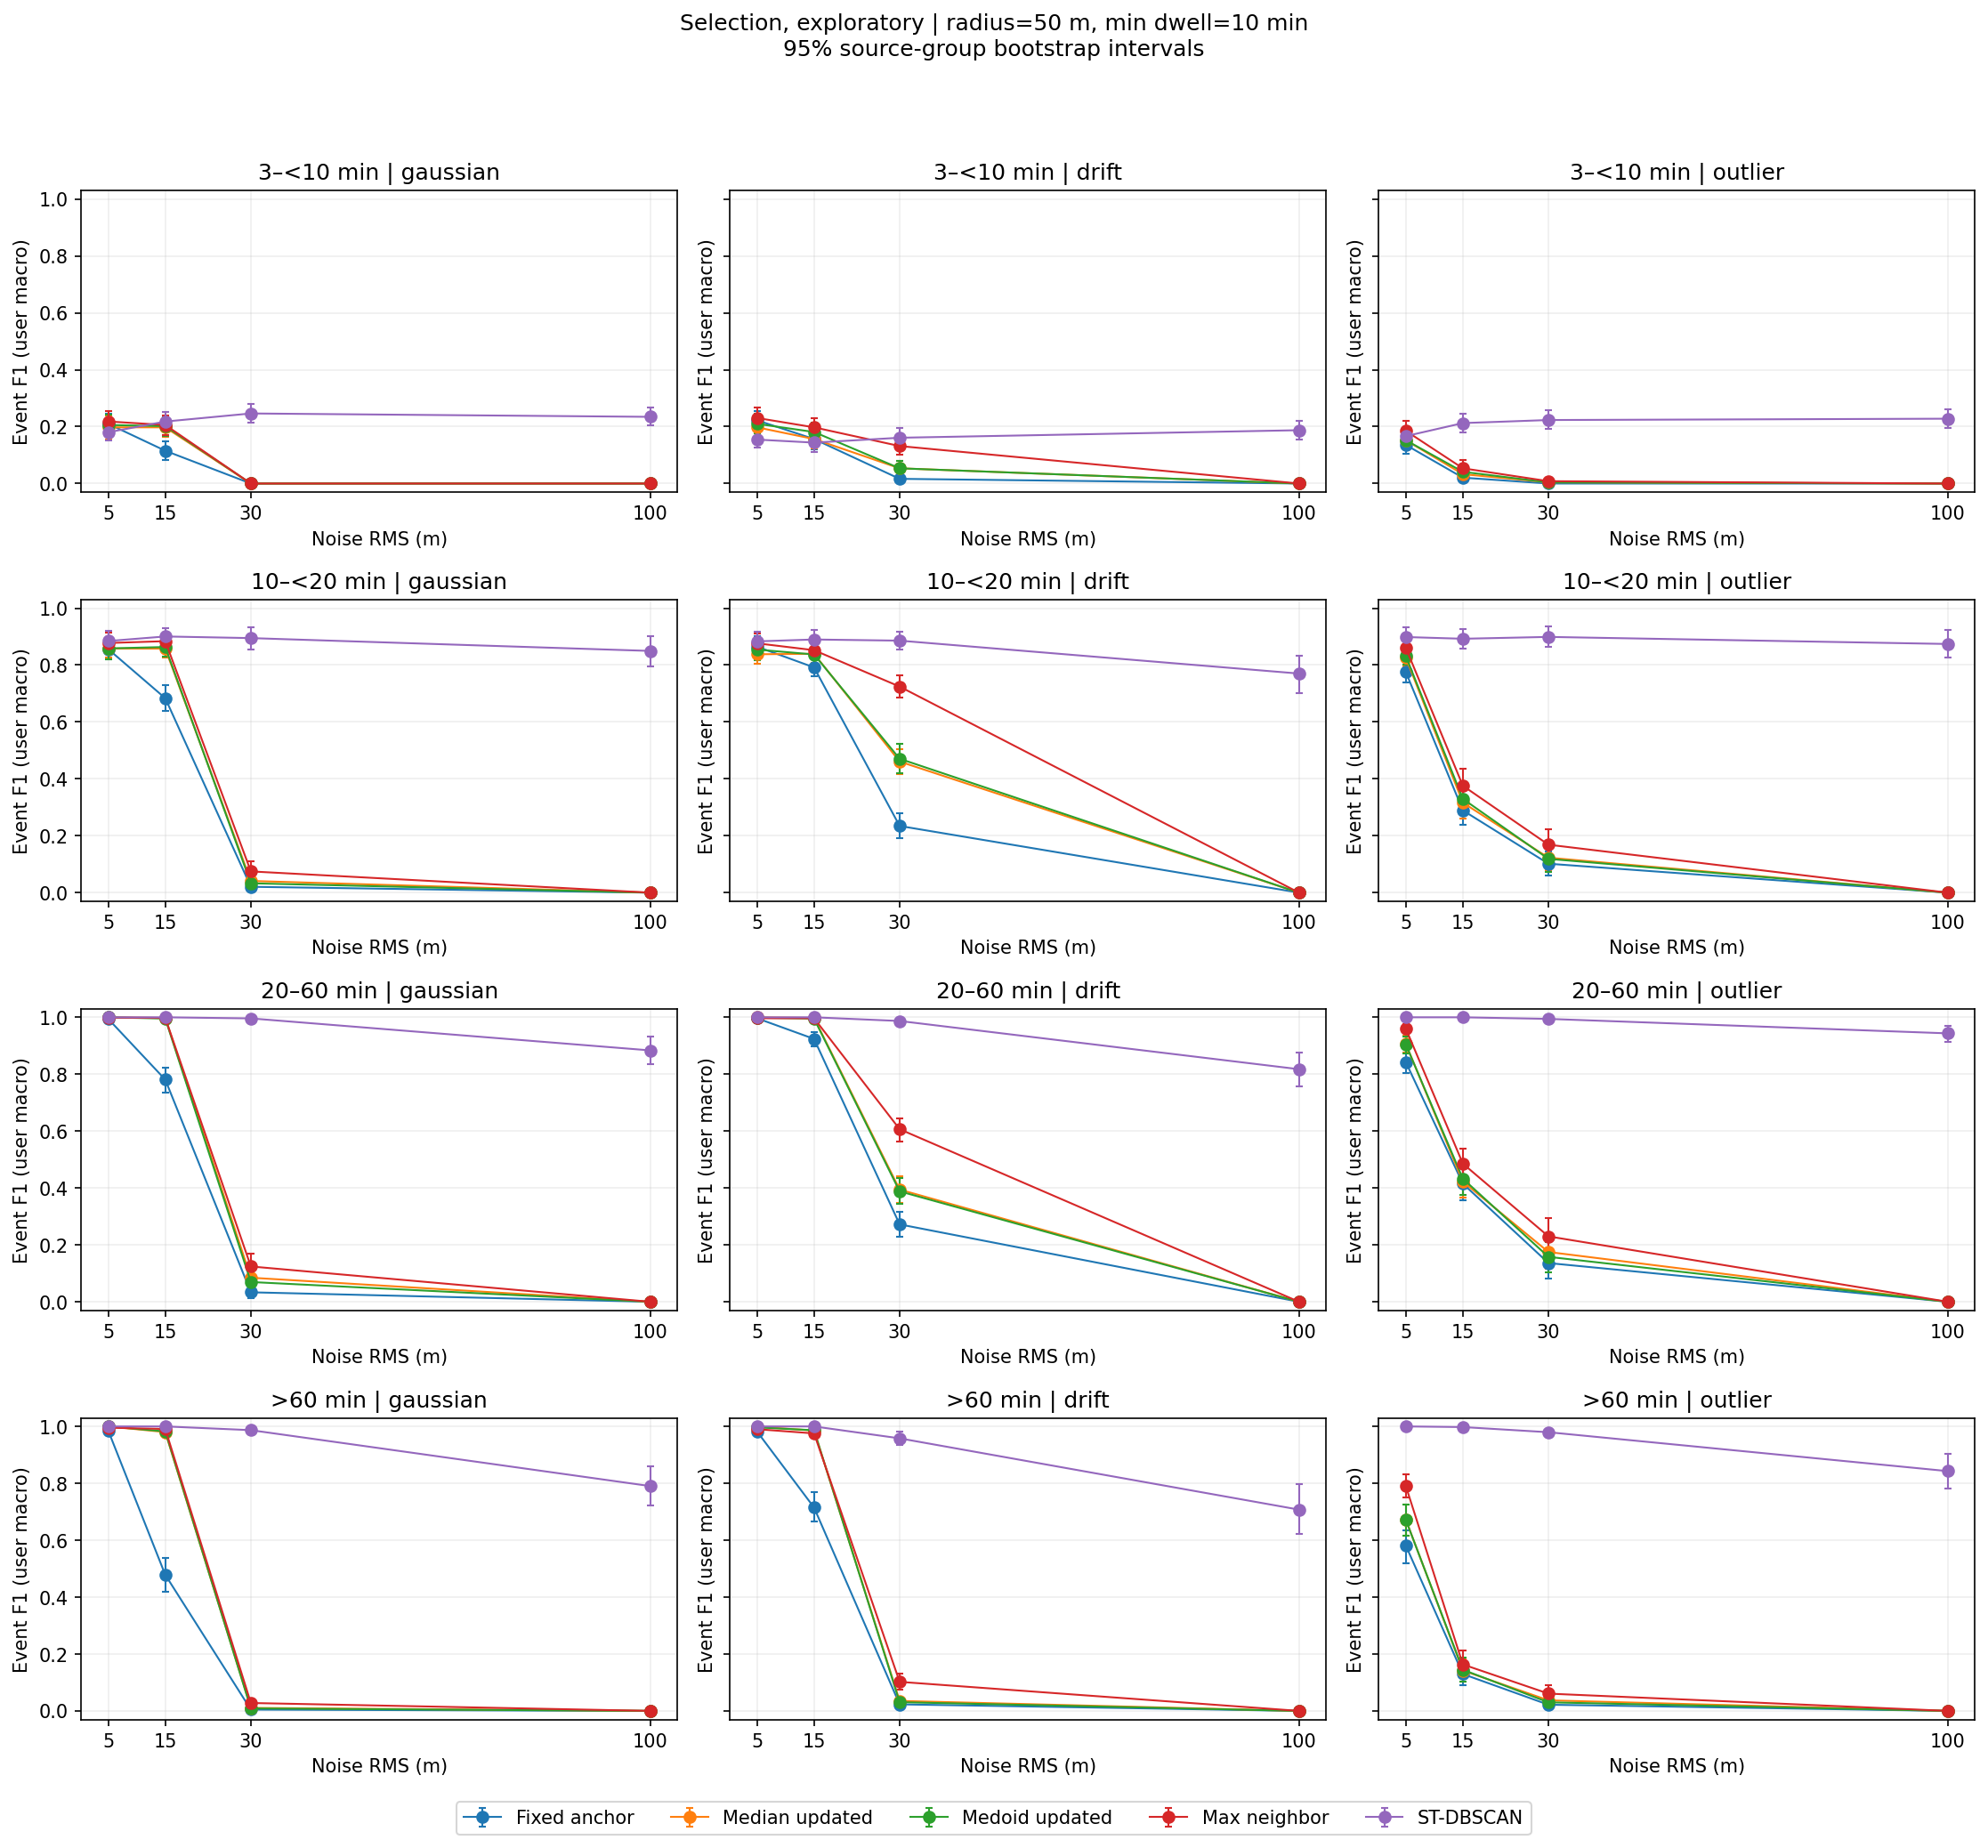

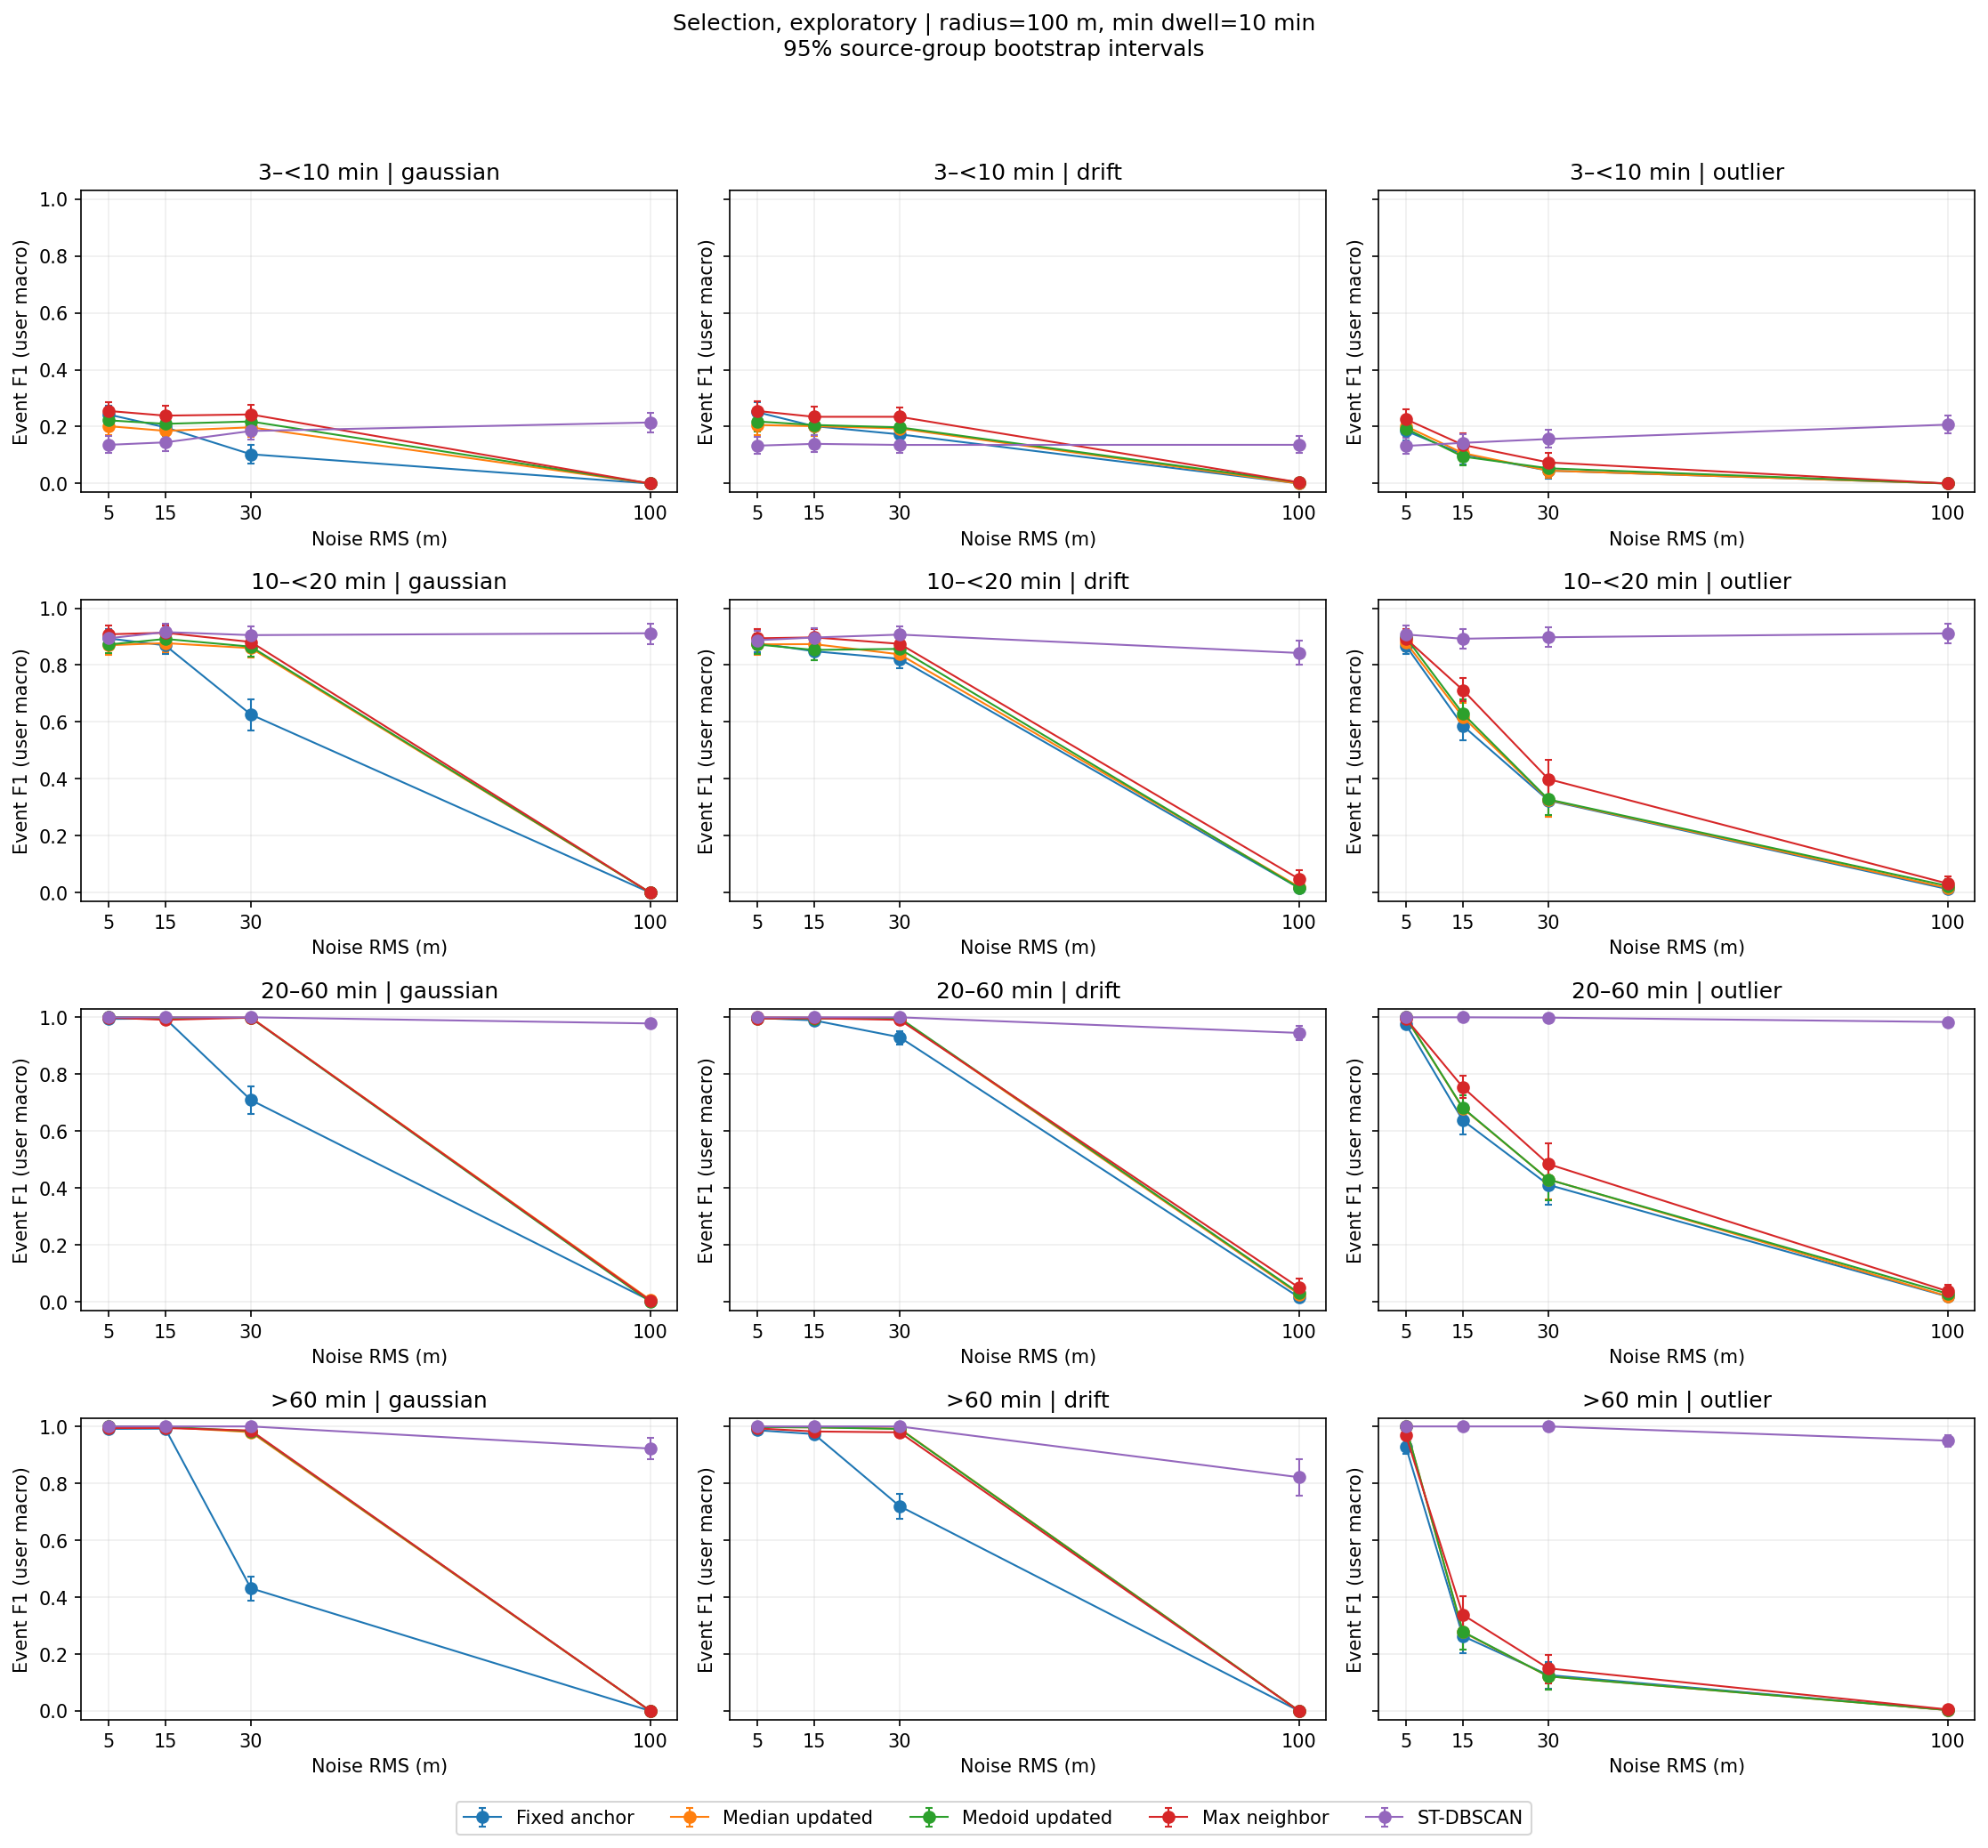

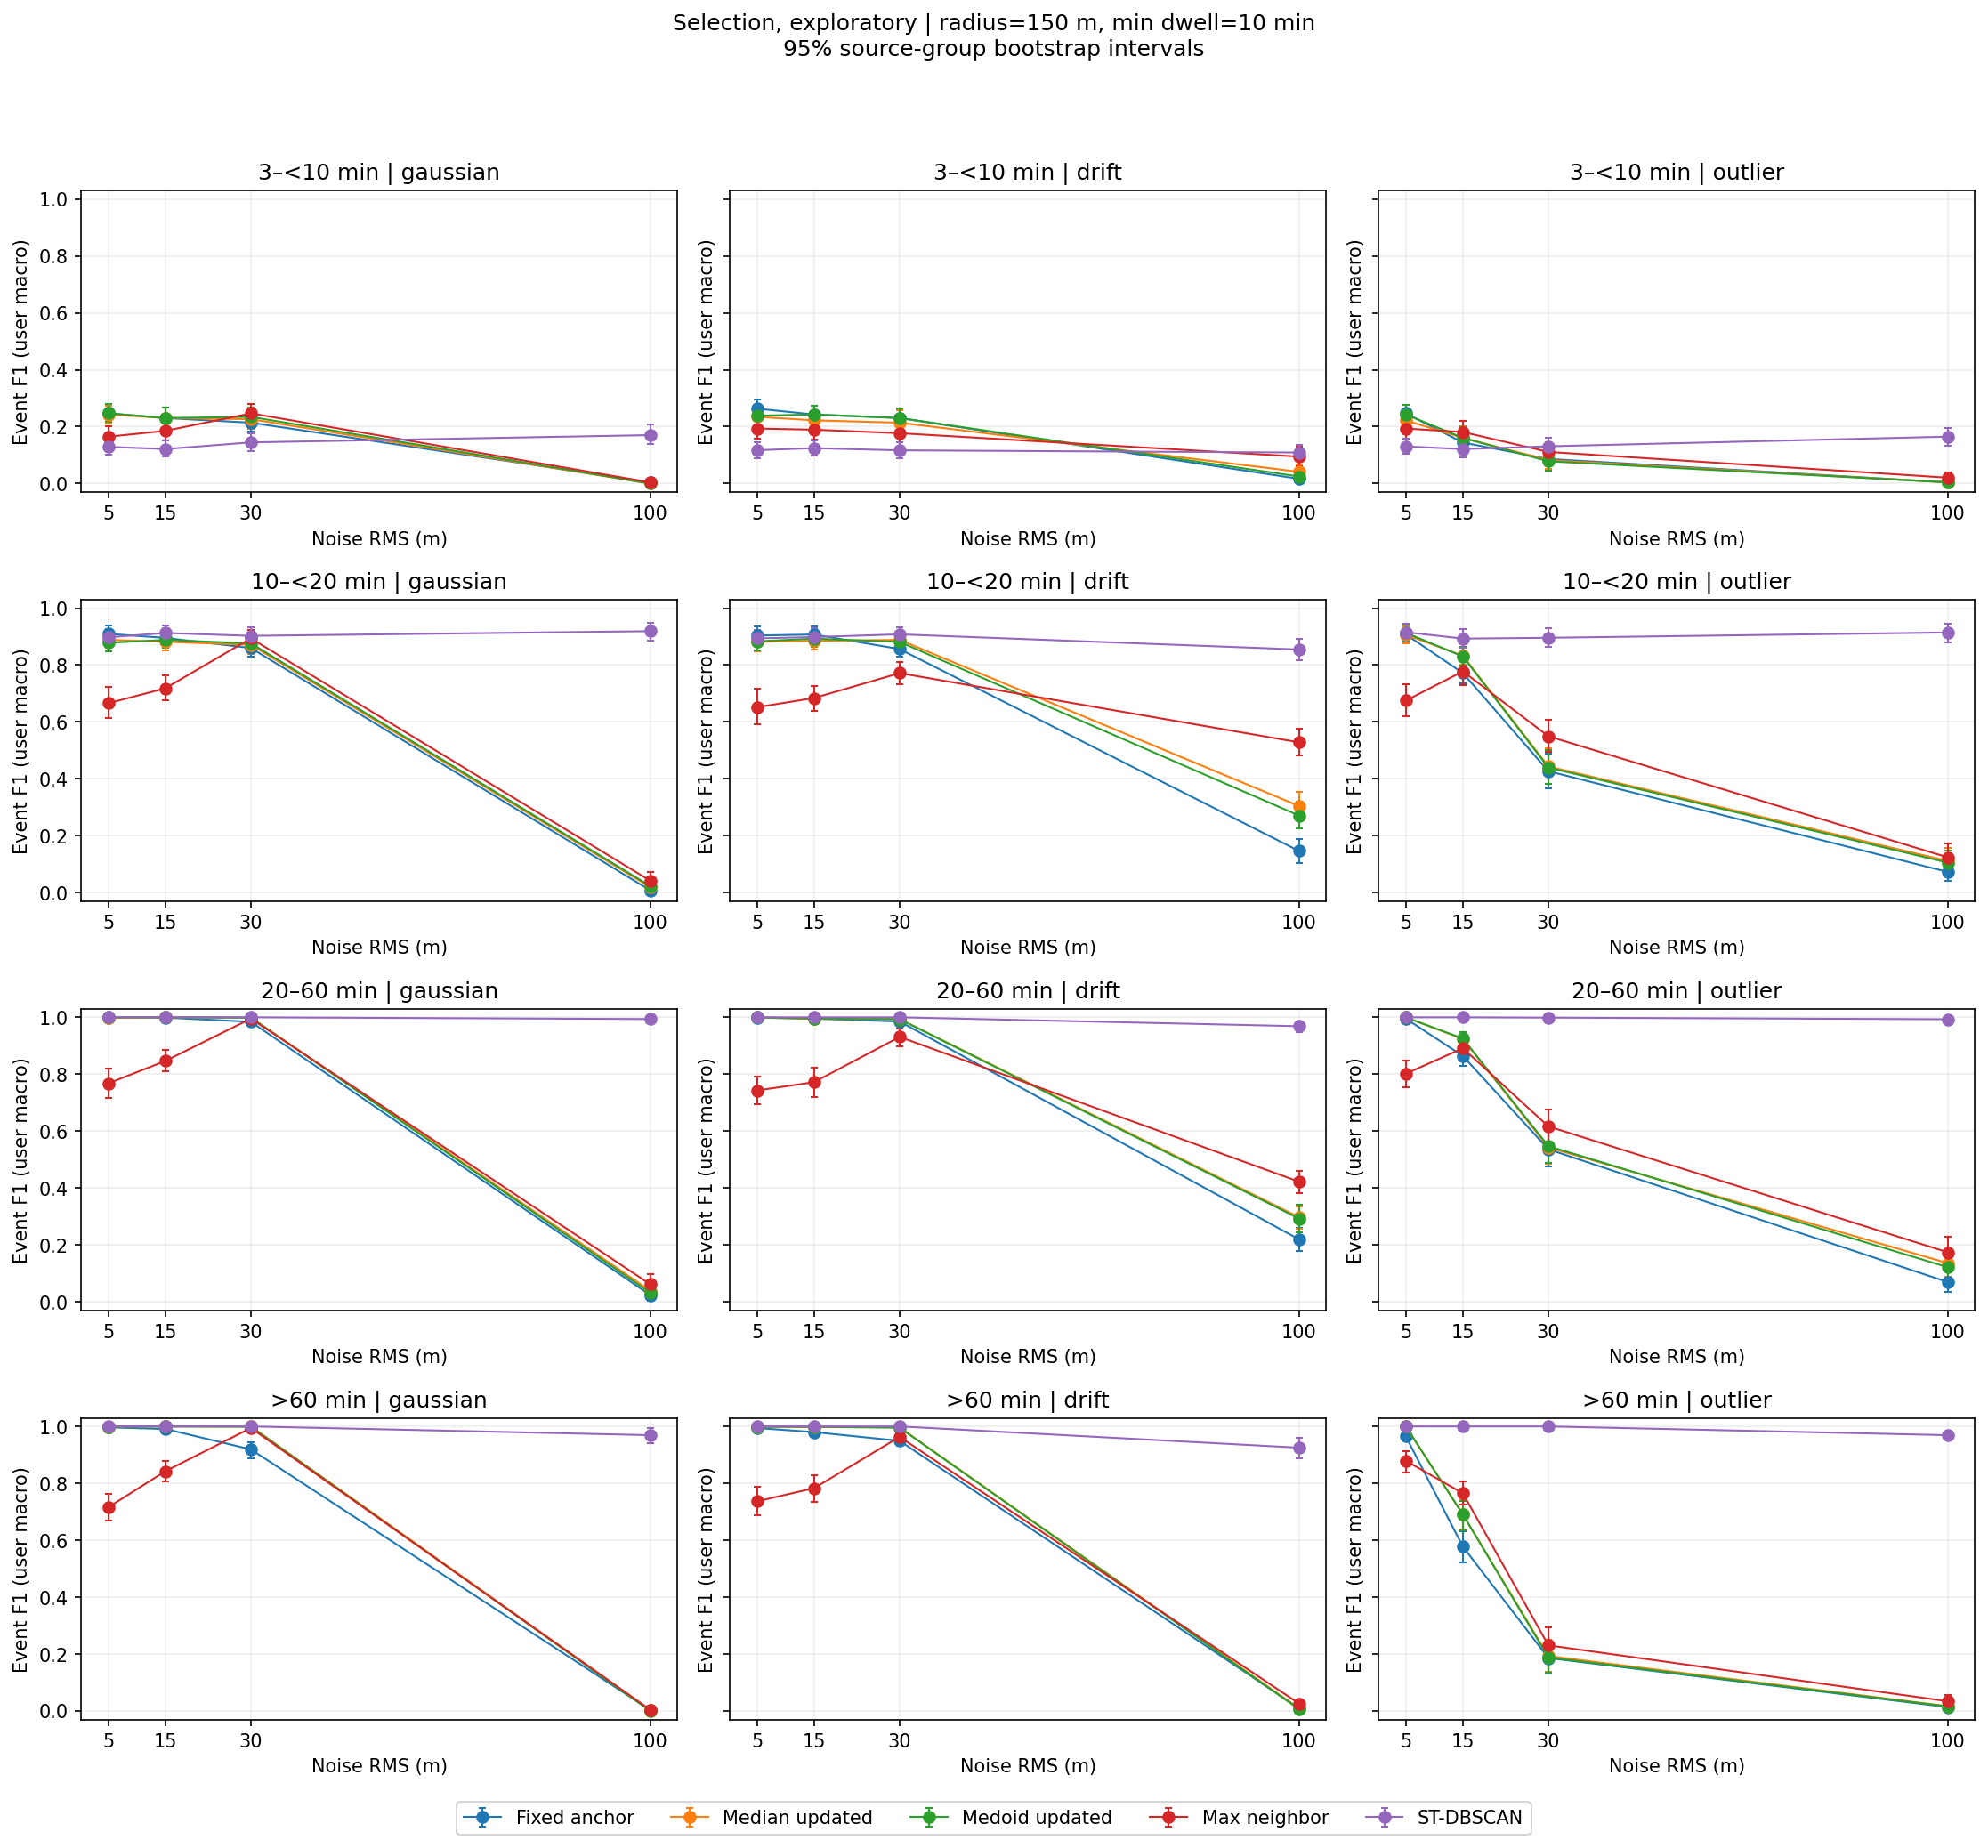

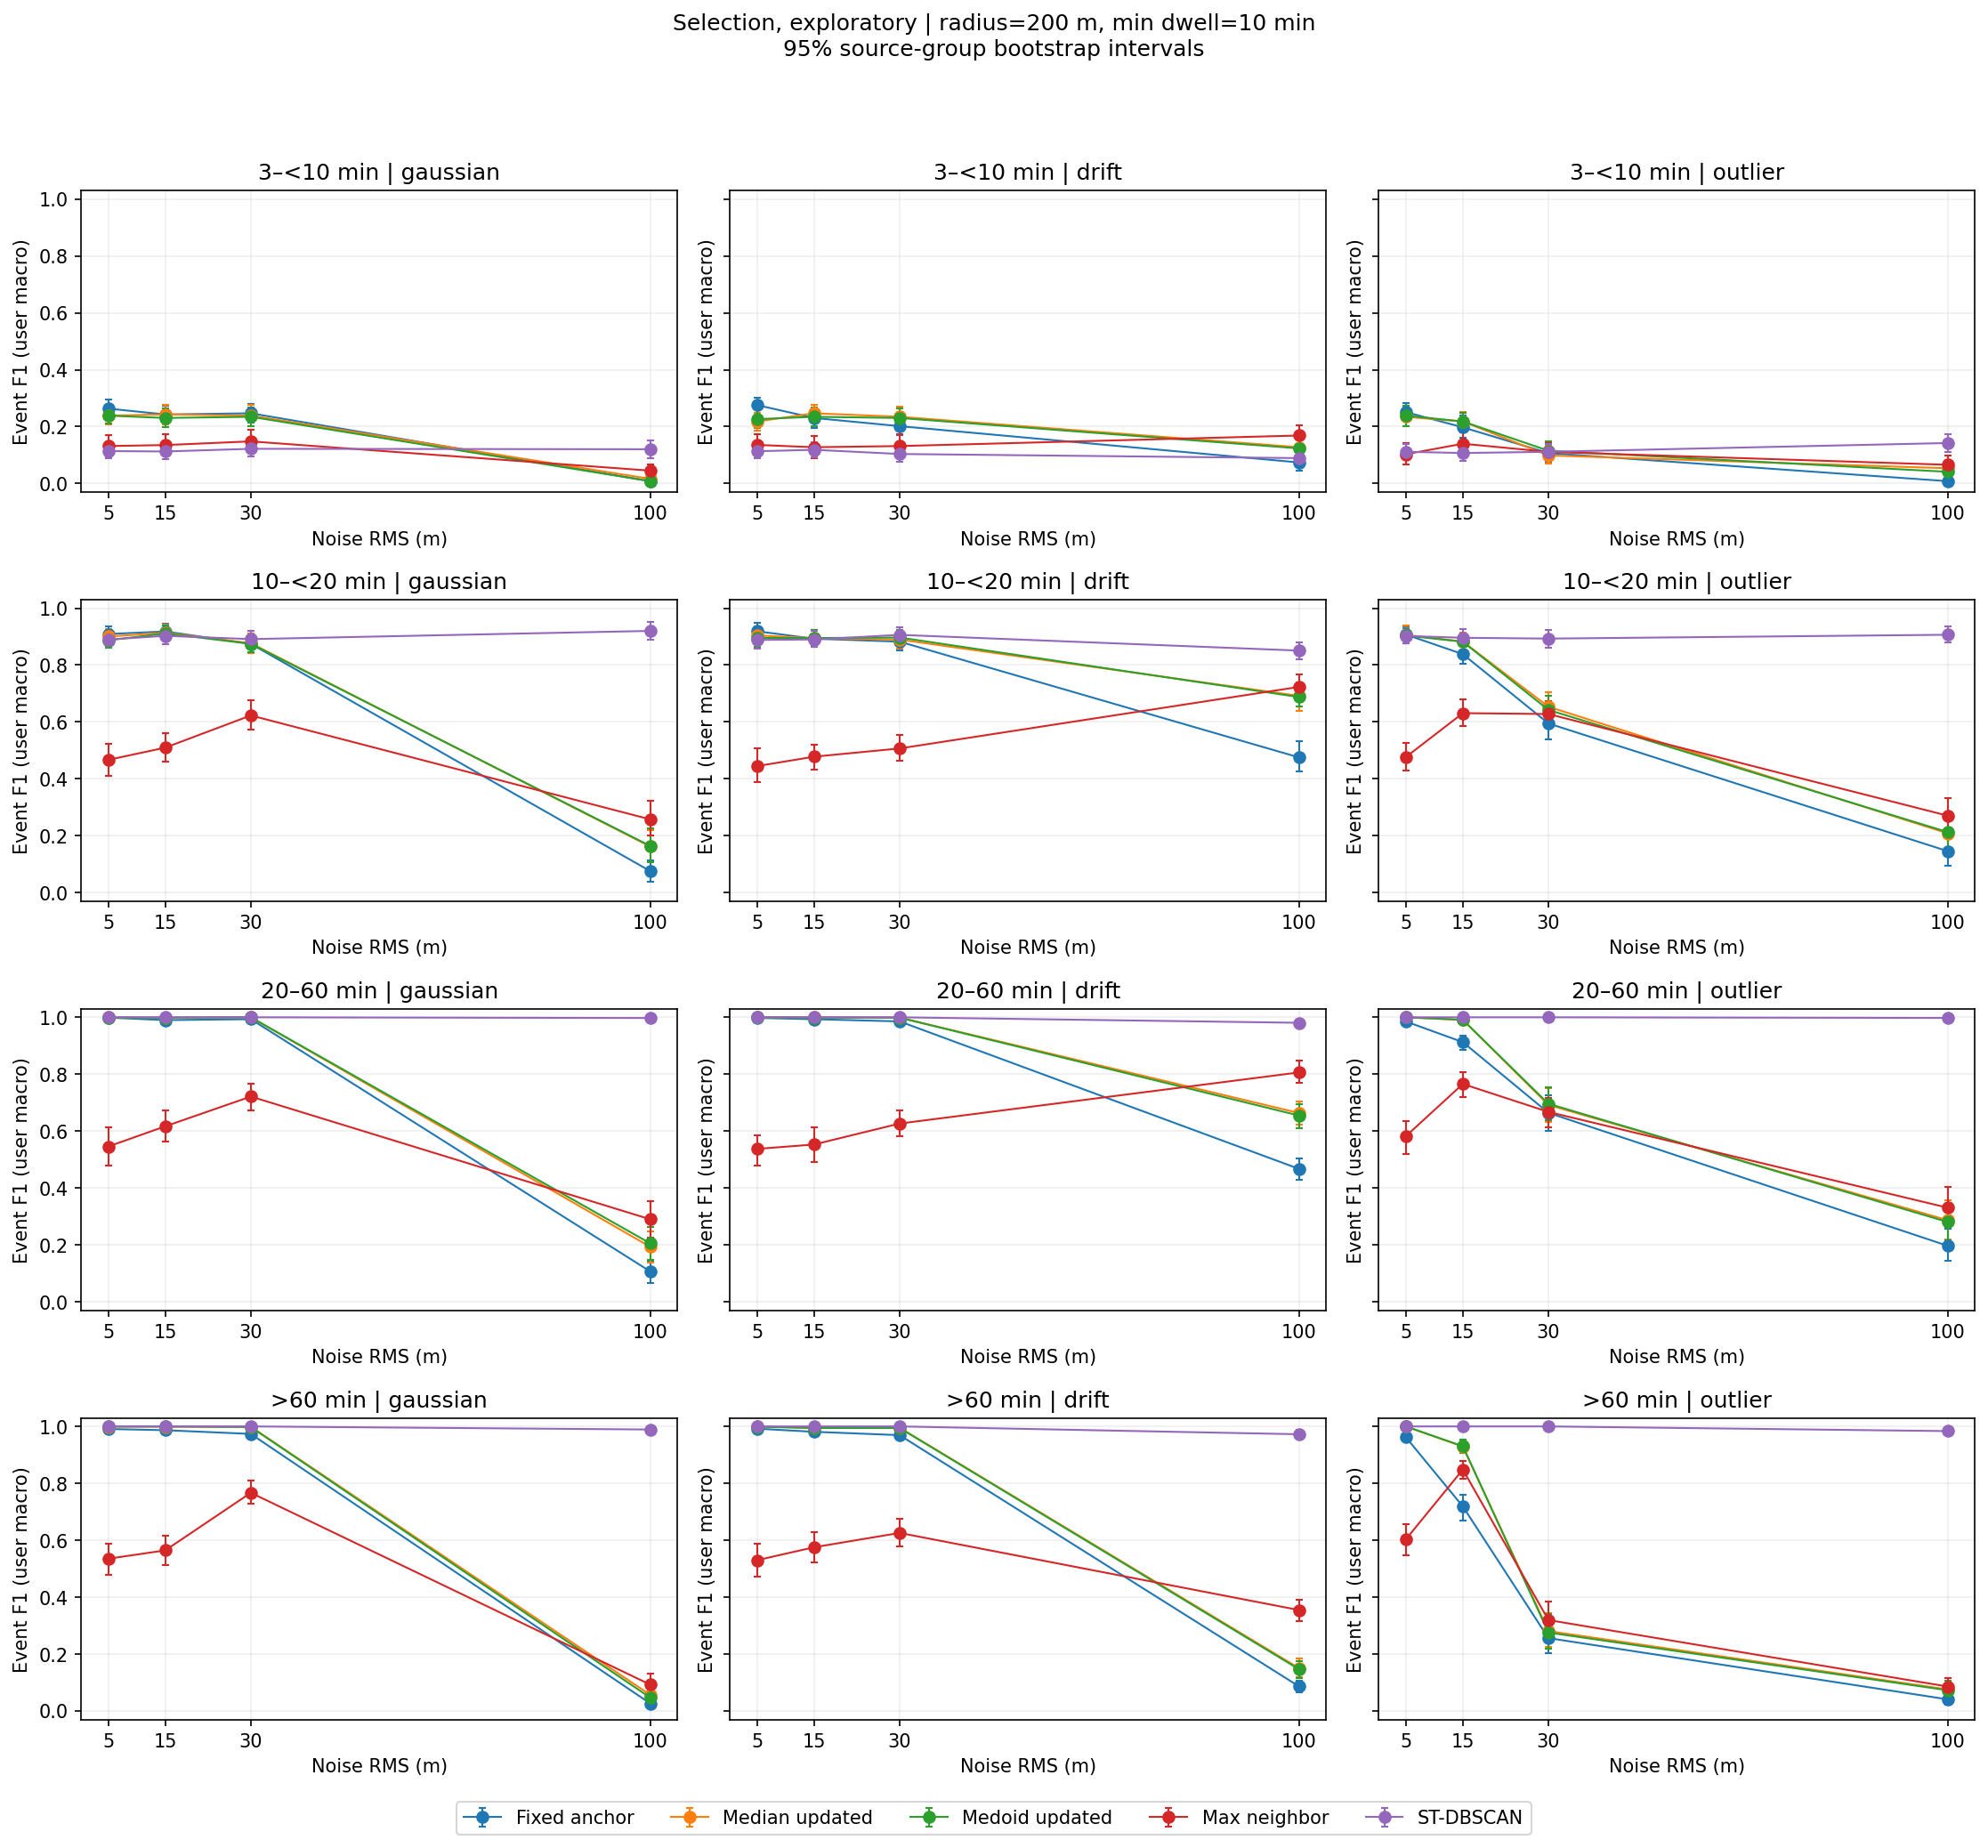

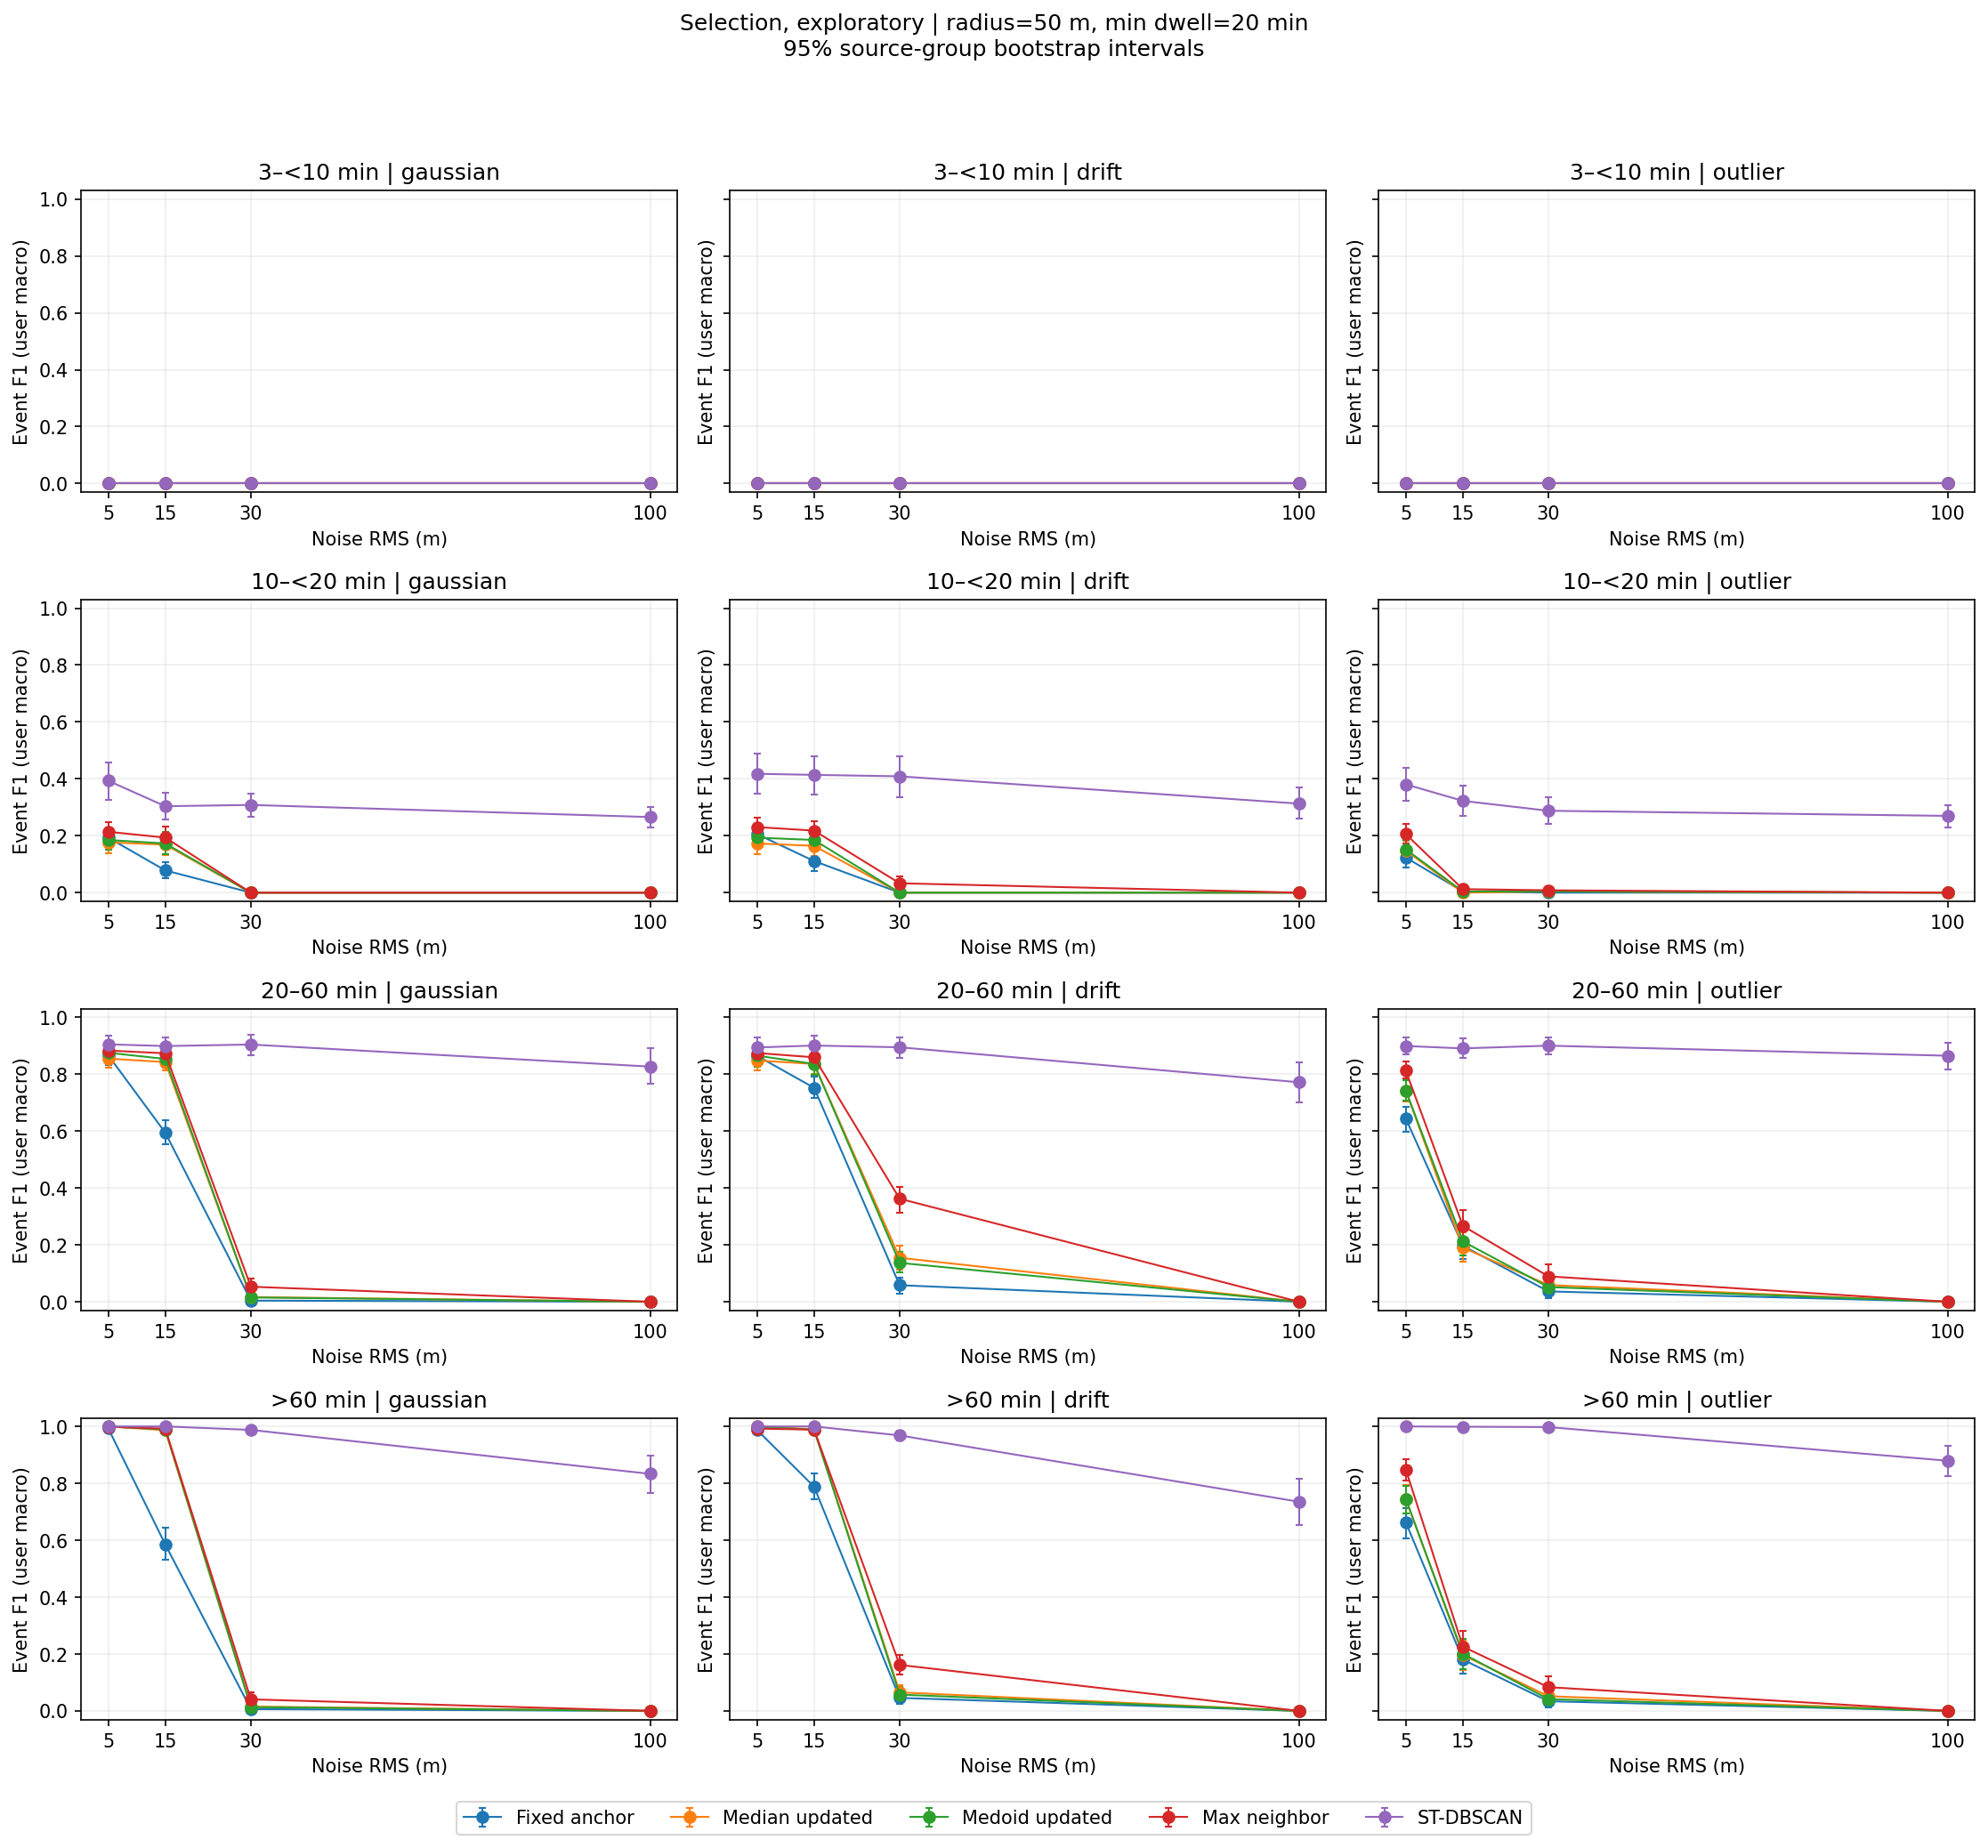

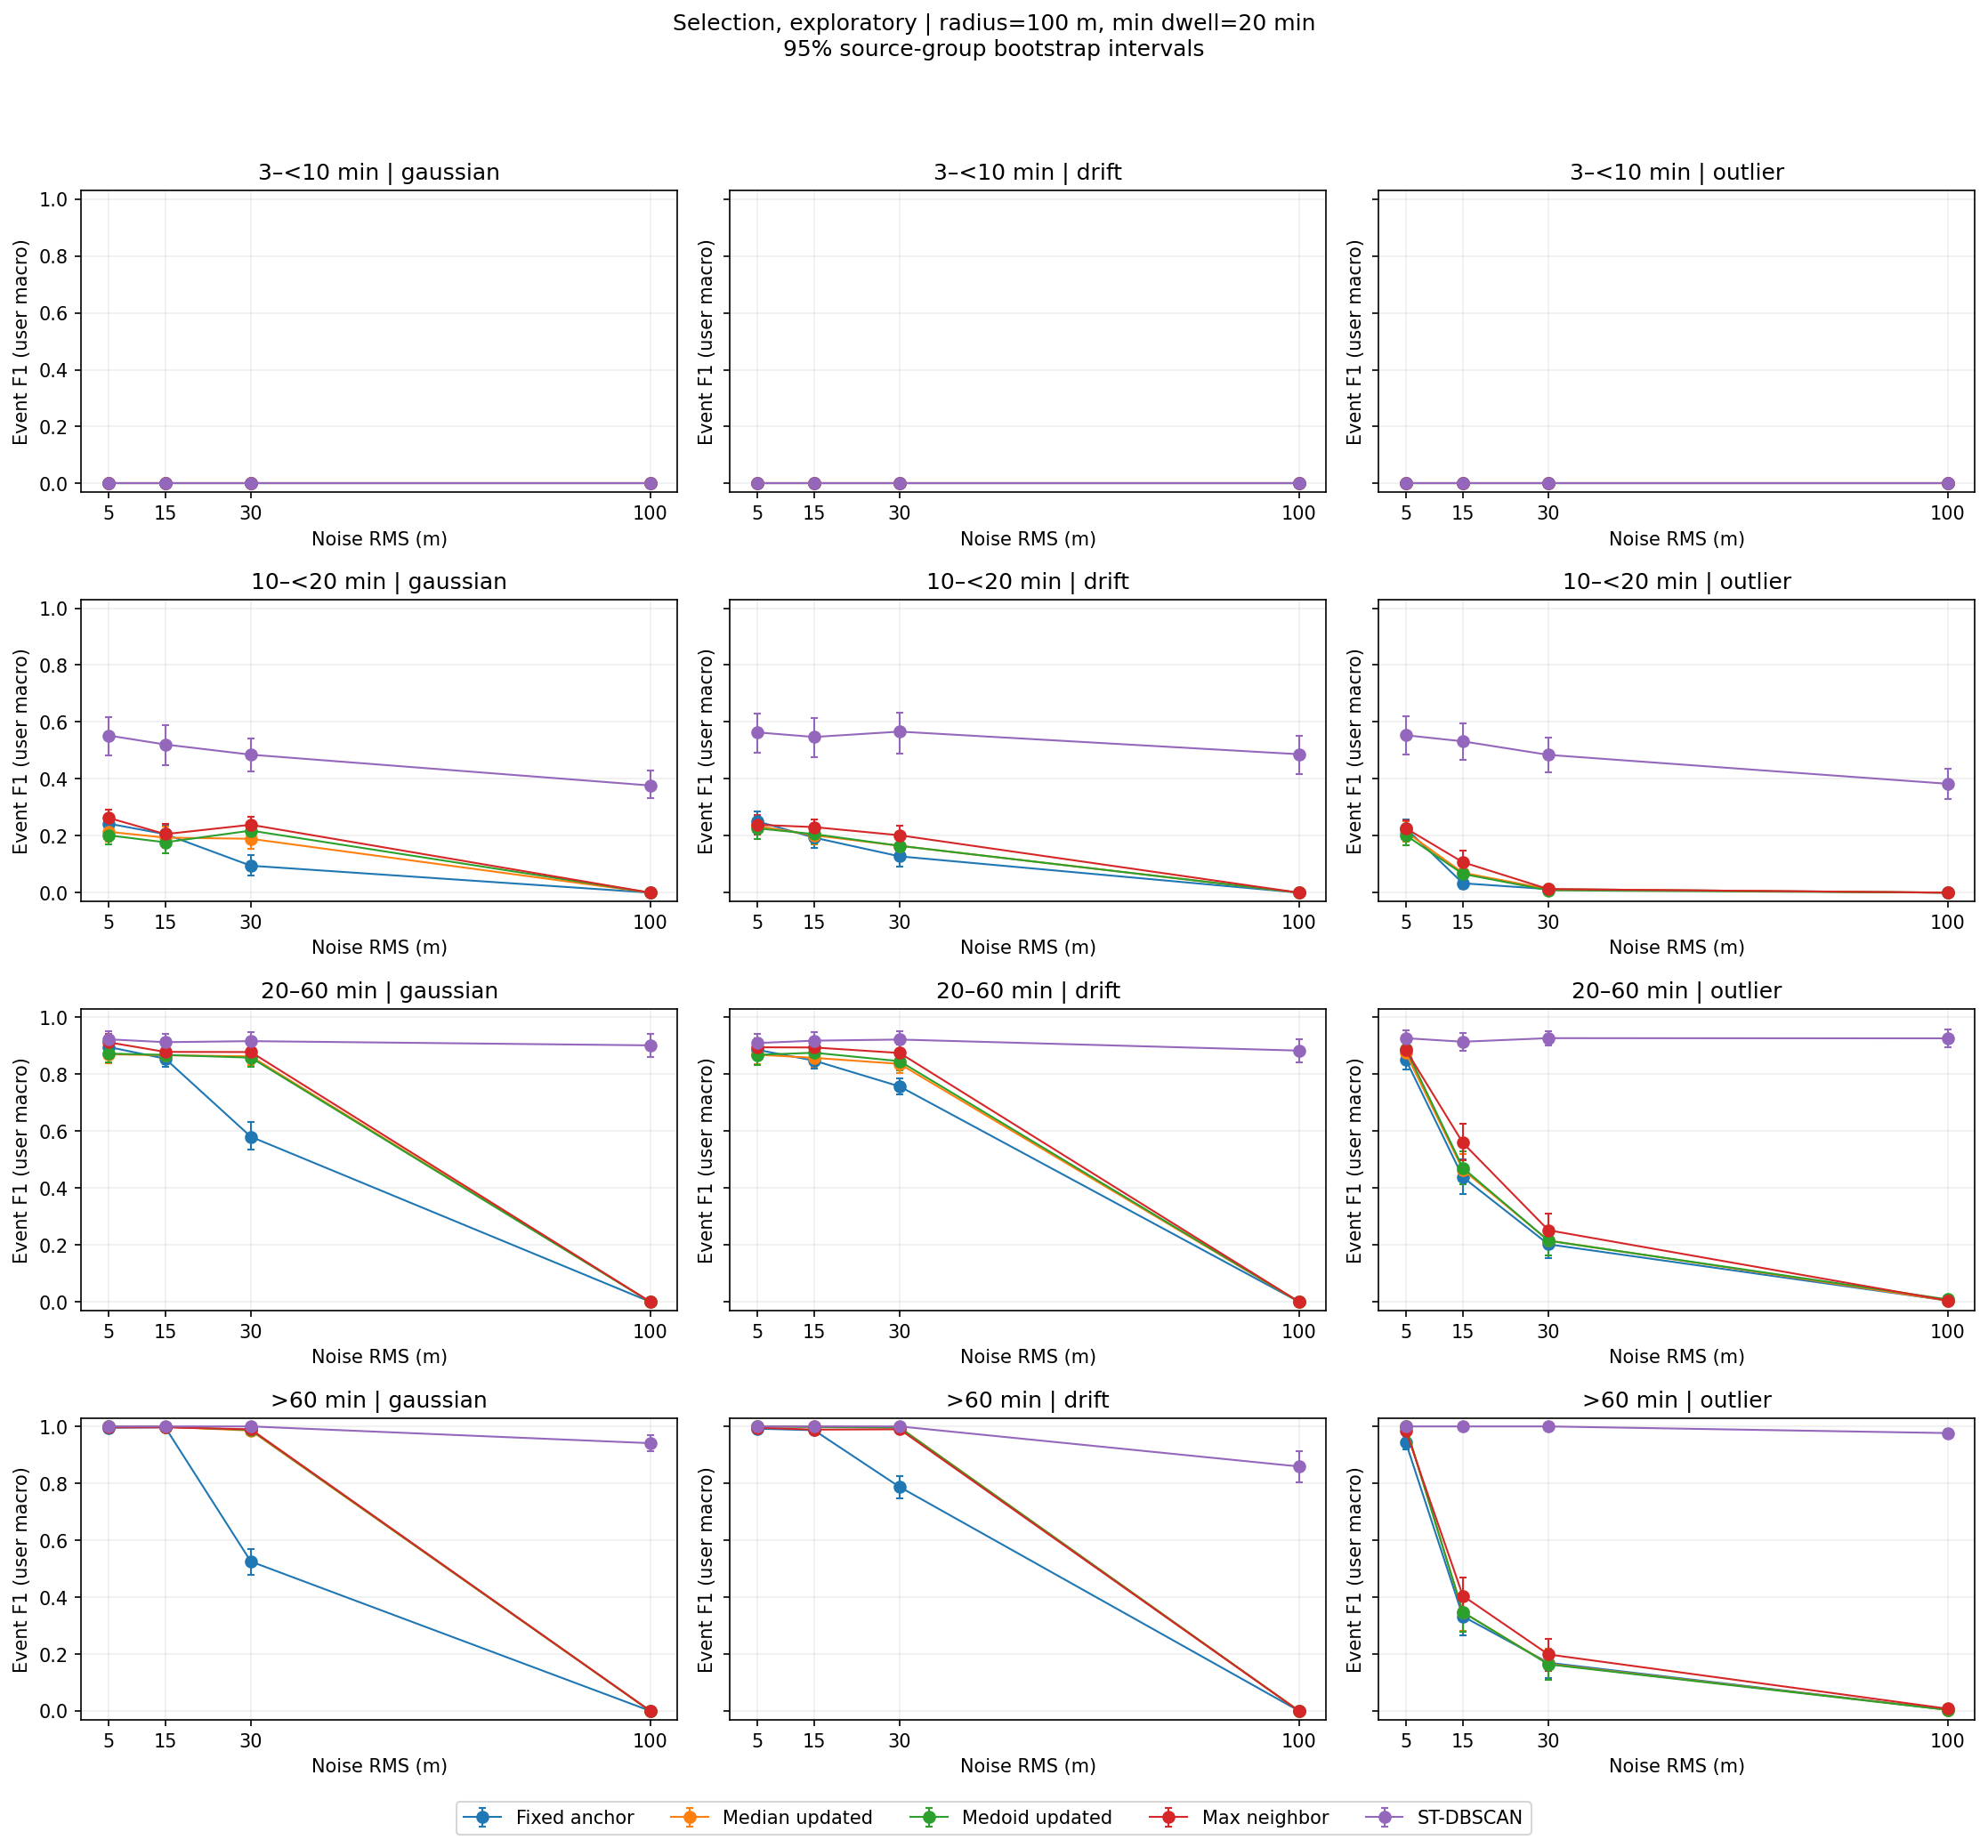

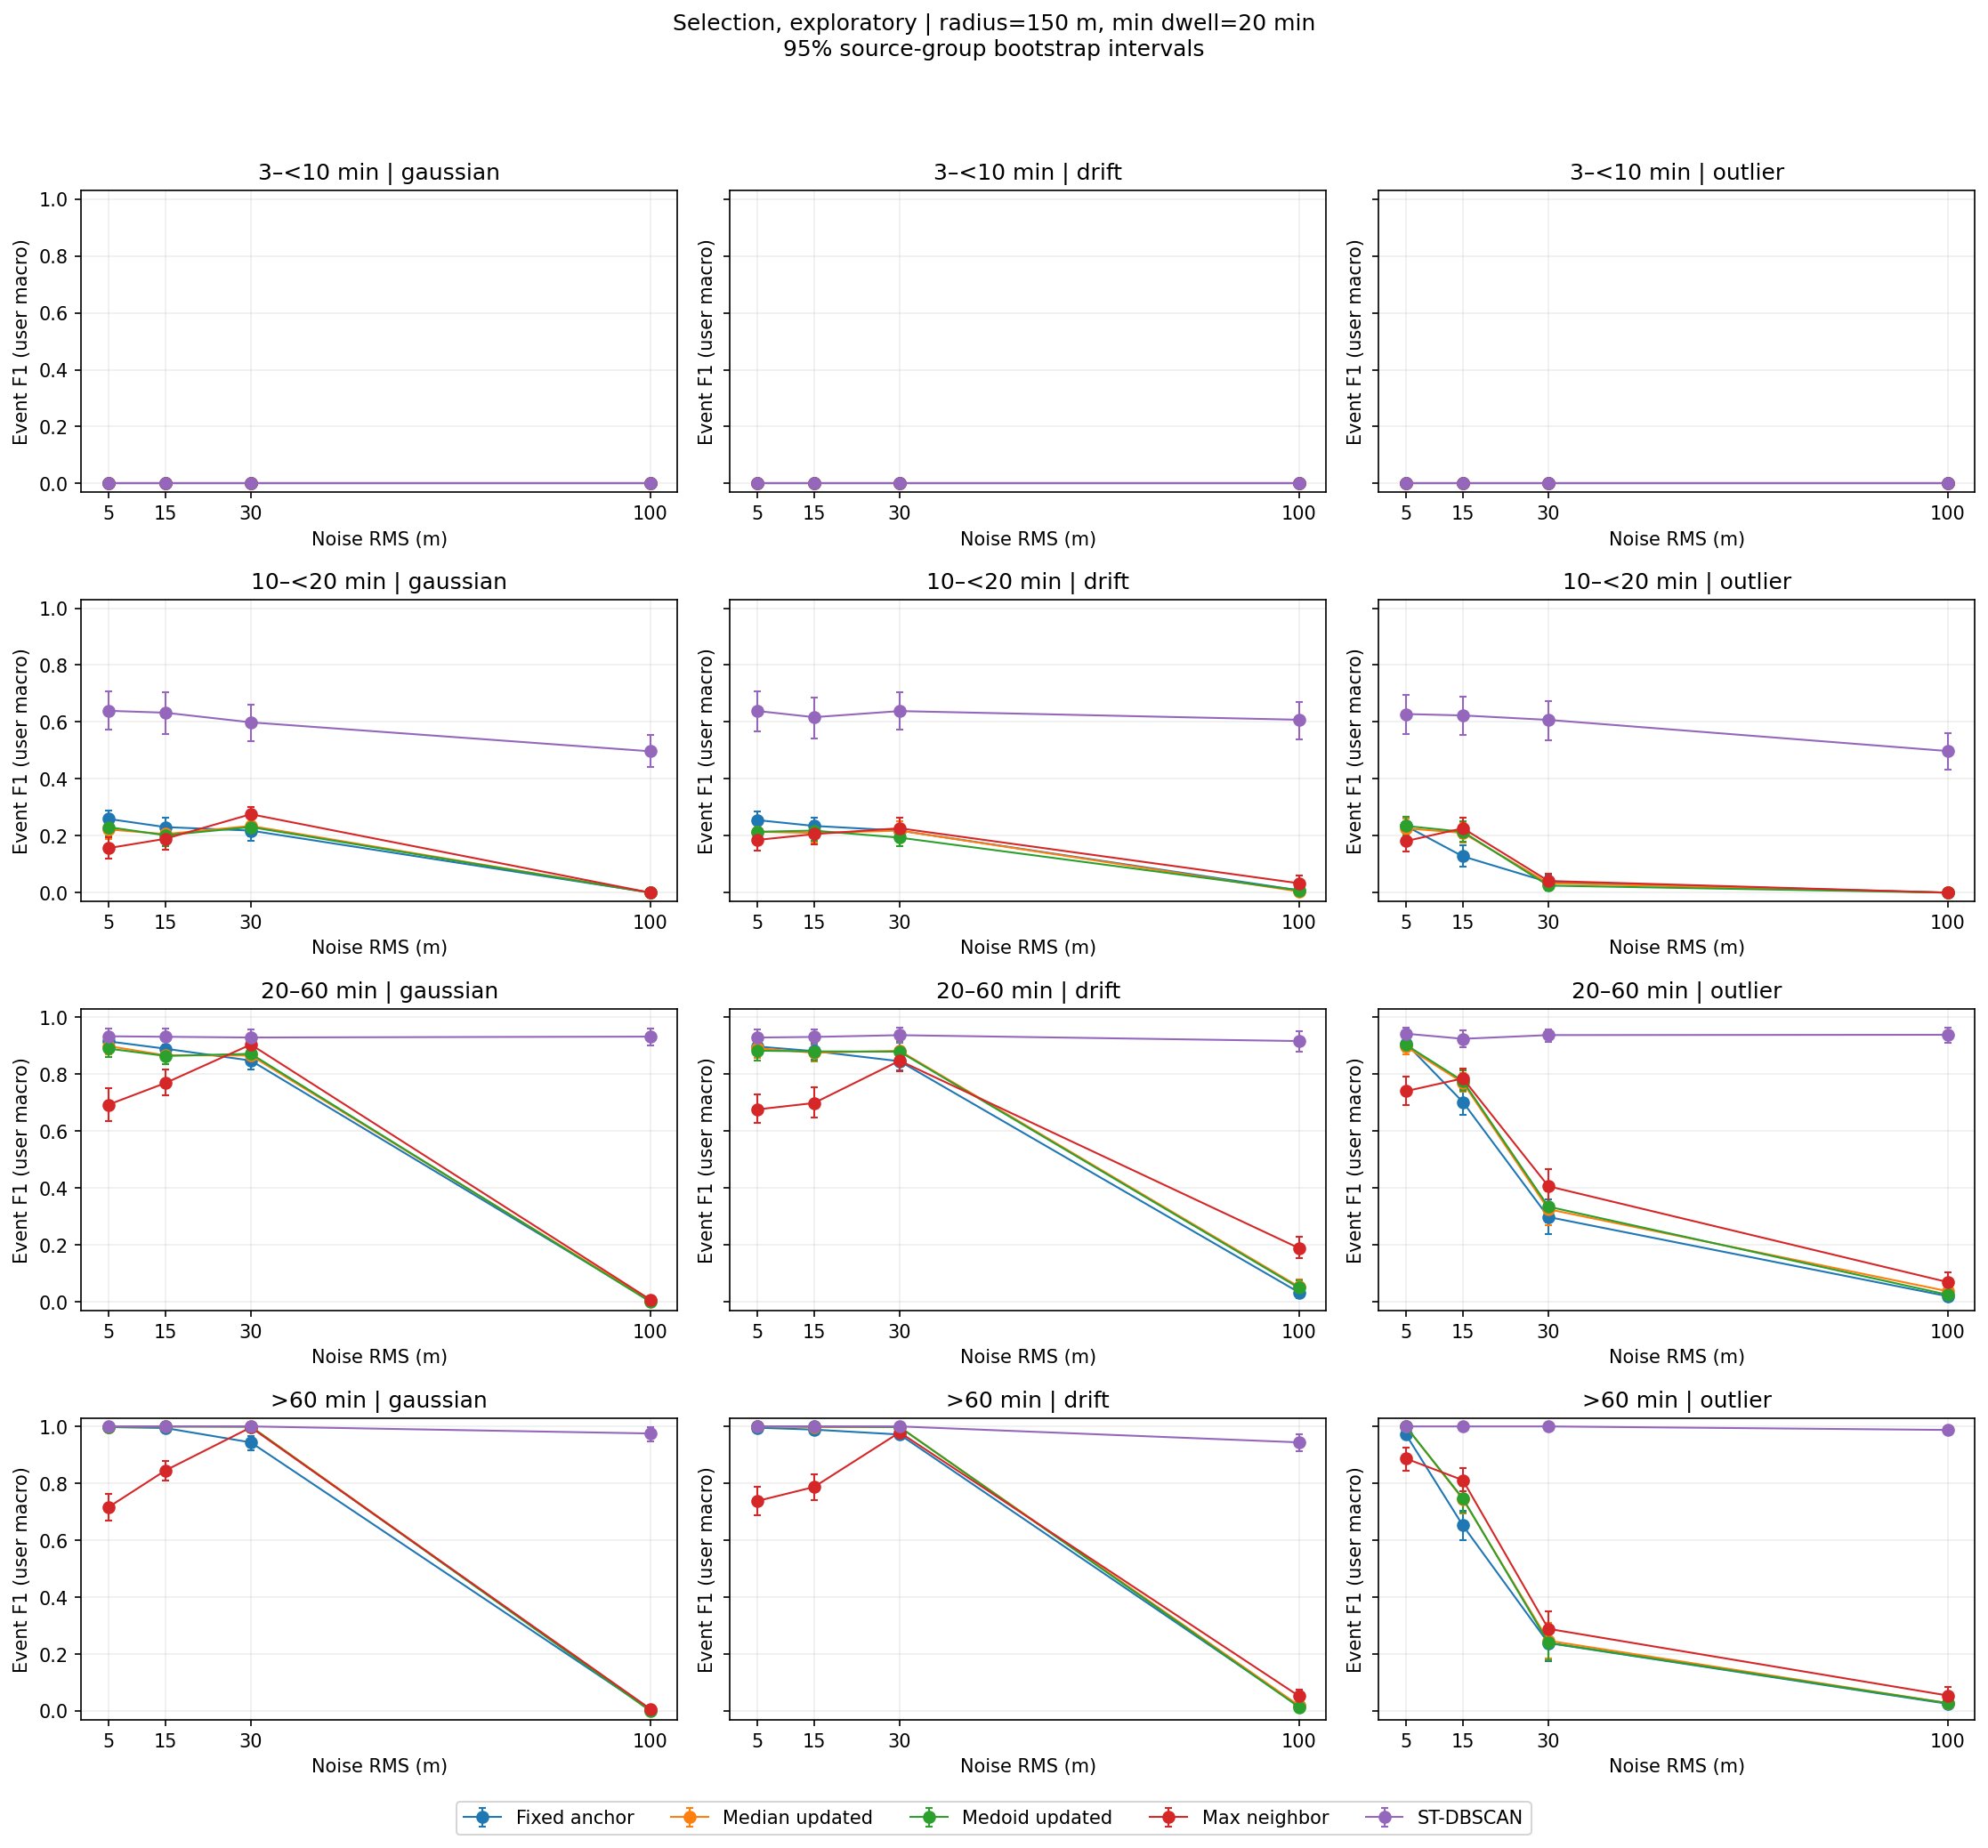

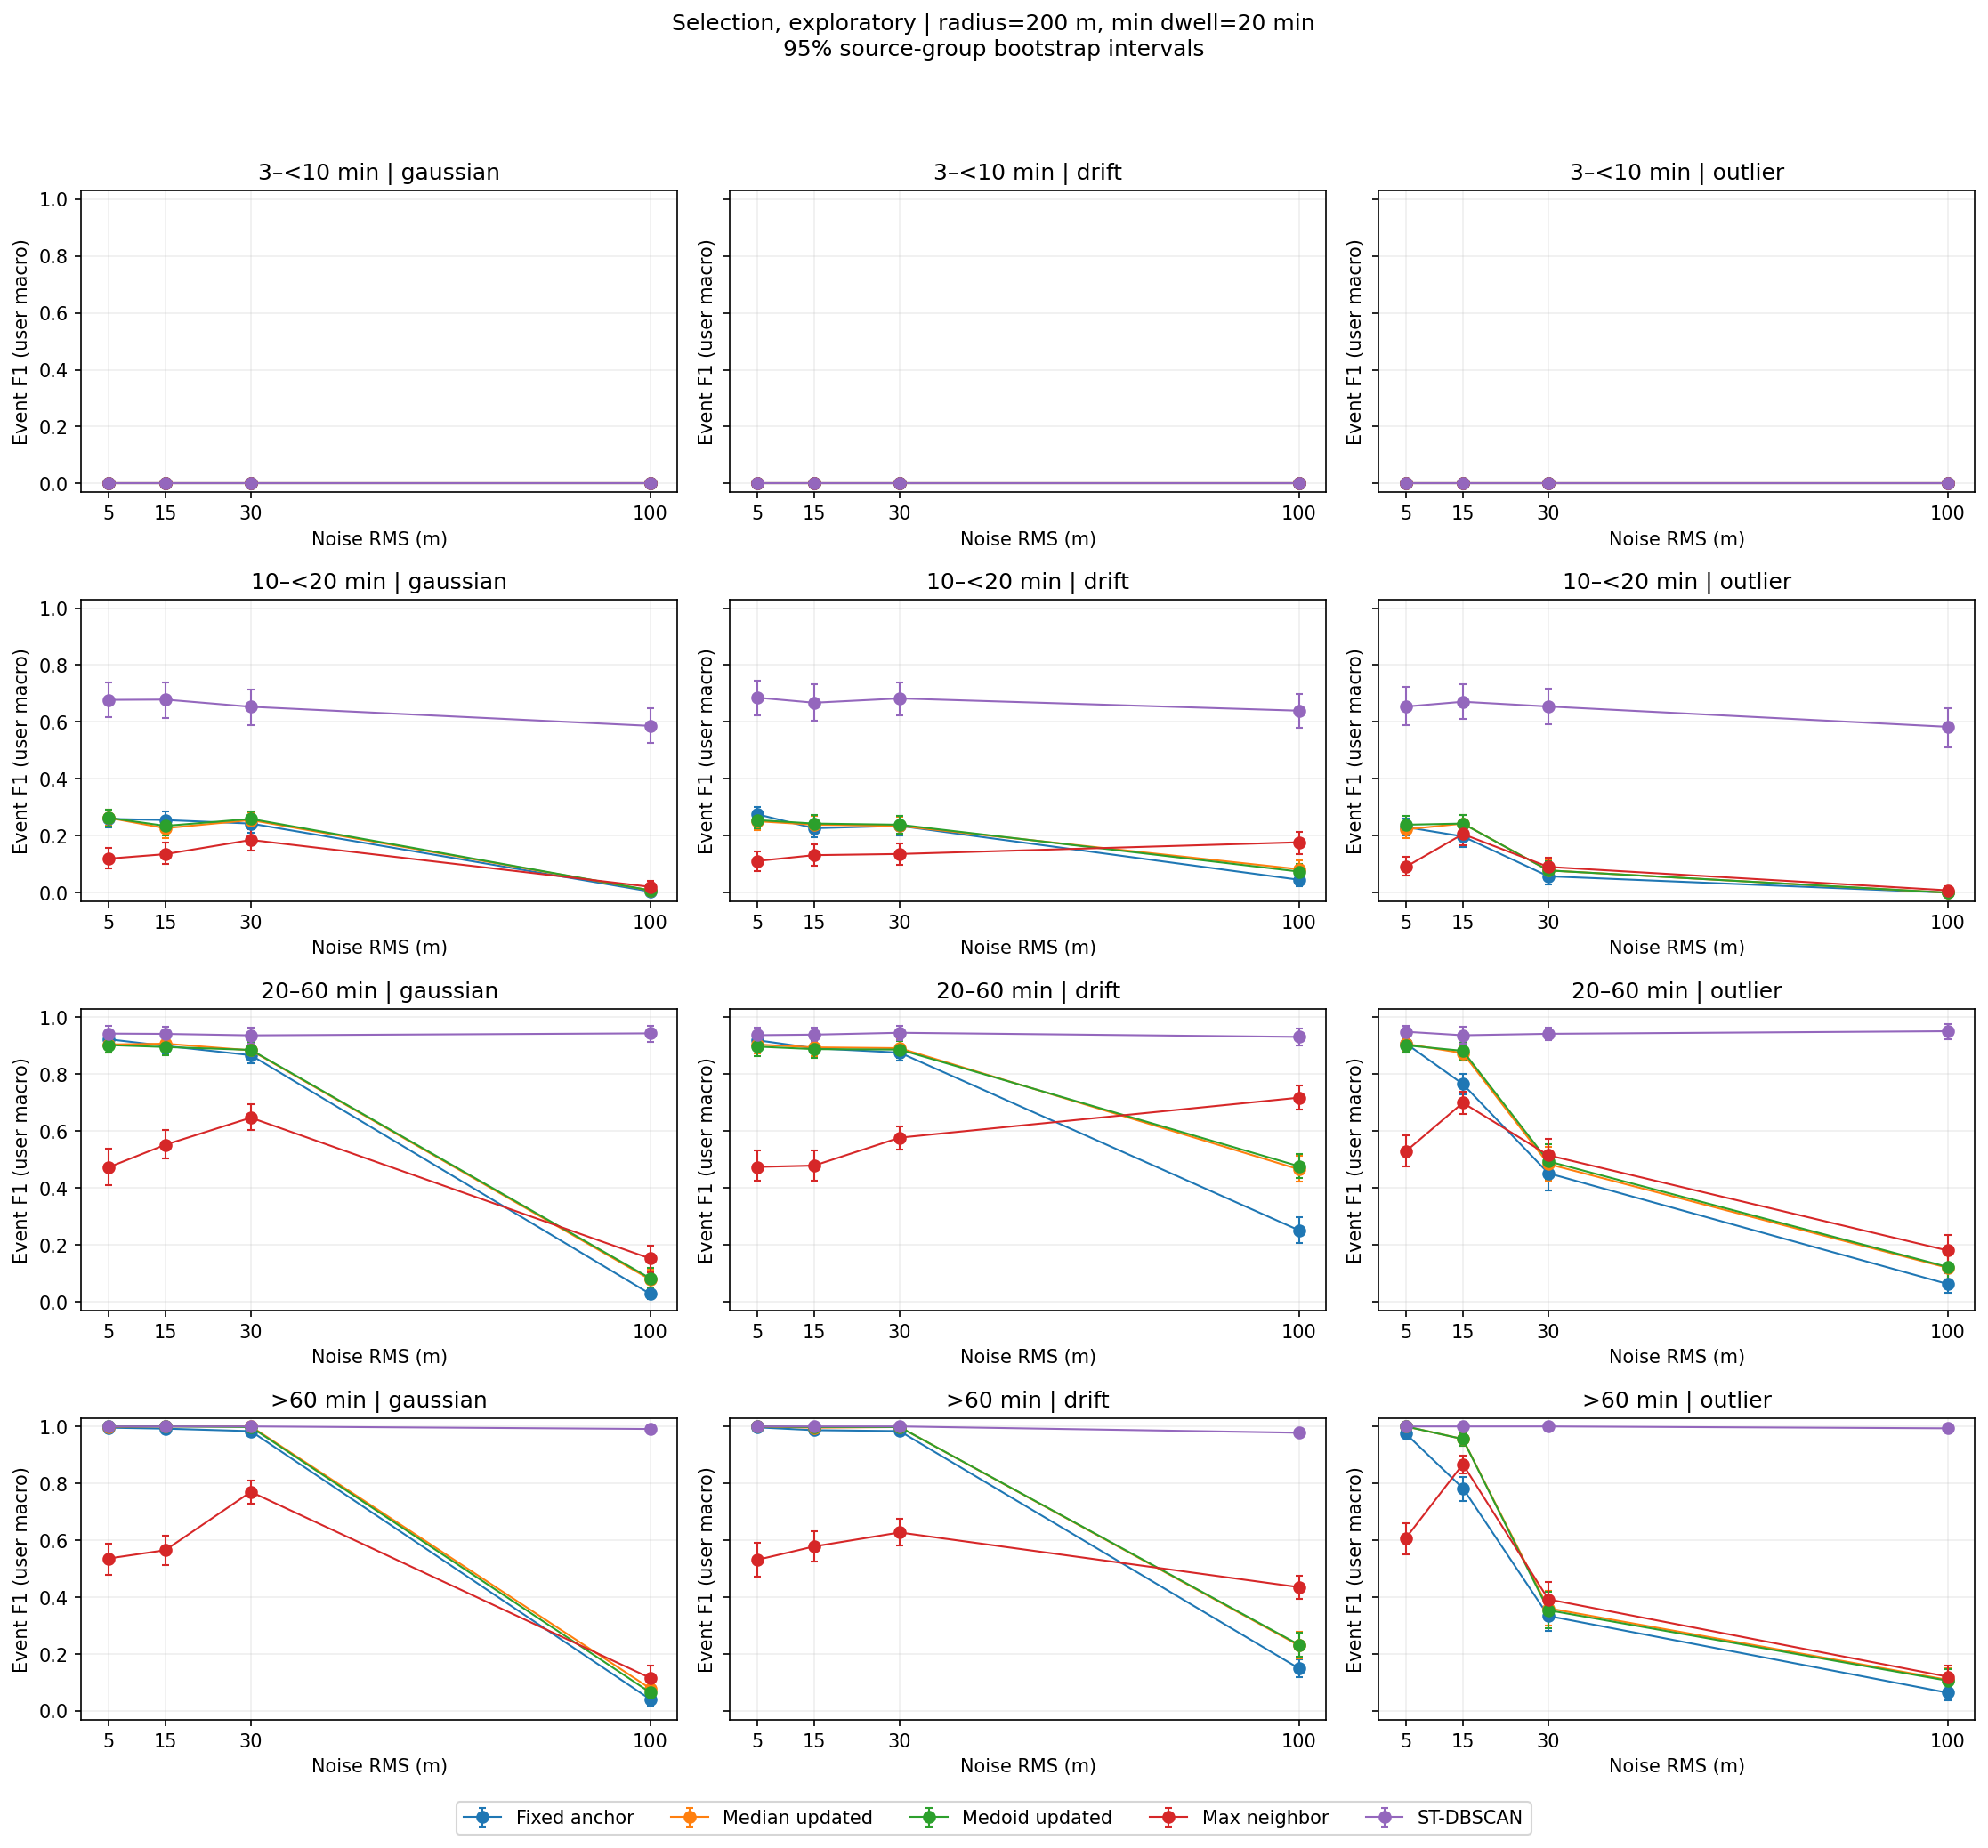

Các figure bổ sung và ST sweep: E:\QUY\Geolife-Trajectories\artifacts\benchmark\b4\run_v1\plots_selection
Compute tích lũy: 10.972/24 giờ; còn 13.028 giờ
Ledger gồm khoản dự trữ lịch sử 3.600 giây từ B2, không phải toàn bộ là runtime đã đo.


In [2]:
# Tự nạp thiết lập khi chạy riêng cell này; giữ nguyên các cờ đã đặt.
from pathlib import Path
import sys
_b4_root = Path(globals().get('ROOT', Path.cwd())).resolve()
if not (_b4_root / 'src/geolife_inference').is_dir():
    _b4_root = _b4_root.parent
if str(_b4_root / 'src') not in sys.path:
    sys.path.insert(0, str(_b4_root / 'src'))
import importlib
from geolife_inference import benchmark_notebook as _b4_notebook
importlib.reload(_b4_notebook).prepare(globals())

synthetic_audit = OUT / 'synthetic_selection/audit.json'
synthetic_done = synthetic_audit.exists() and jobs.readj(synthetic_audit)['status'] == 'completed'
if RUN_SUMMARIZE and synthetic_done:
    stage('summary_selection', lambda: jobs.summarize(ROOT, OUT))
    macro = pd.read_csv(OUT / 'summary_selection/macro_by_cell.csv')
    display(macro[['config_id', 'cell_id', 'group', 'users', 'f1', 'f1_ci_low', 'f1_ci_high',
                   'precision', 'recall', 'fp_per_hour']].head(25))
summary_audit = OUT / 'summary_selection/audit.json'
summary_done = summary_audit.exists() and jobs.readj(summary_audit)['status'] == 'completed'
if RUN_PLOTS and synthetic_done and summary_done:
    stage('plots_selection', lambda: plot_runner.render(ROOT, OUT))
    for dwell in [10, 20]:
        for radius in [50, 100, 150, 200]:
            display(Image(filename=str(OUT / f'plots_selection/config_r{radius}_d{dwell}_f1.png')))
    print('Các figure bổ sung và ST sweep:', OUT / 'plots_selection')
if not synthetic_done:
    print('Job tổng hợp chưa completed; chưa dựng bảng/plot đầy đủ. Xem trạng thái ở mục 3.')
show_budget()


## 5. Dữ liệu thật — 40 tổ hợp chung

Đặt `RUN_REAL=True`, `REAL_WORKERS=10` ở đầu cell dưới để khởi động hoặc nhận diện job nền.
Mỗi tiến trình xử lý một user với đủ 40 cấu hình. Tổng RAM coordinator và worker chịu cùng trần
min(8 GiB, nửa RAM khả dụng đầu attempt), không nhân trần theo số worker.

Đọc cleaned vote20 một lượt để tạo cache theo user, giữ nguyên giá trị float64 và thứ tự trajectory.
Các worker dùng nguyên detector, baseline parity và phép tính metric đã khóa. Giữ checkpoint user completed.
Không chạy lại preprocessing/grouping/Home/Office. User đang dở ở lượt dừng phải chạy lại.

Mục 3a tự chuyển sang theo dõi dữ liệu thật khi có audit real. Interrupt cell theo dõi chỉ tắt bảng.
Dừng job nền bằng `real_parallel.request_stop(OUT)`; chạy lại mục 5 với `RESUME=True` để tiếp tục.

Chỉ khi real completed, chạy lại mục 5 để dựng bảng/plot selection. Báo stay, dwell, overlap/split/merge
và phủ định bằng nhãn phương tiện. Độ ổn định ở mức detector, không chứng minh một radius cụ thể.
Job kiểm kê đủ 182 user; bảng chọn cấu hình chỉ dùng user nguồn selection. Kết quả này không đo accuracy.

Bổ sung thực thi 2026-11-06: thời gian thực hiện trộn tuần tự/song song chỉ dùng mô tả.
Cổng runtime (d) chưa xác nhận bằng lượt song song; chưa chọn winner hoặc mở final từ timing này.


In [ ]:
RUN_PLOTS = True
RUN_REAL = True
# Tự nạp thiết lập khi chạy riêng cell này; giữ nguyên các cờ đã đặt.
from pathlib import Path
import sys
_b4_root = Path(globals().get('ROOT', Path.cwd())).resolve()
if not (_b4_root / 'src/geolife_inference').is_dir():
    _b4_root = _b4_root.parent
if str(_b4_root / 'src') not in sys.path:
    sys.path.insert(0, str(_b4_root / 'src'))
import importlib
from geolife_inference import benchmark_notebook as _b4_notebook
importlib.reload(_b4_notebook).prepare(globals())

if RUN_REAL and synthetic_done:
    if REAL_WORKERS > 1:
        display(real_parallel.launch(ROOT, OUT, workers=REAL_WORKERS, resume=RESUME))
        display(real_parallel.status(OUT))
    else:
        stage('real', lambda: jobs.run_real(ROOT, OUT, resume=RESUME))
    if completed('real'):
        stage('real_description_selection', lambda: jobs.describe_real(ROOT, OUT))
        if RUN_PLOTS:
            stage('plots_real_selection', lambda: plot_runner.render_real(ROOT, OUT))
        display(pd.read_csv(OUT / 'real_description_selection/counts_motor_runtime.csv'))
        display(pd.read_csv(OUT / 'real_description_selection/plateau.csv'))
        if RUN_PLOTS:
            for title, filename in [
                ('Số stay trung vị mỗi user', 'stays_user_median.png'),
                ('Tổng giờ dwell trung vị mỗi user', 'dwell_user_median_hours.png'),
                ('Tỷ lệ thời lượng stay trùng nhãn phương tiện cơ giới', 'r_motor_user_macro.png'),
            ]:
                print(title)
                display(Image(filename=str(OUT / 'plots_real_selection' / filename)))
    else:
        print('Job dữ liệu thật đang chạy nền. Chạy cell theo dõi ở mục 3a để xem tiến độ tự cập nhật.')
        print('Chạy lại mục 5 sau khi completed để dựng bảng/plot; không chạy lại user đã xong.')
    show_budget()
elif RUN_REAL:
    print('Chờ synthetic_selection completed; chưa khởi động dữ liệu thật.')
else:
    print('Dữ liệu thật đang tắt. Đặt RUN_REAL=True và REAL_WORKERS=10 rồi chạy cell này khi sẵn sàng.')


real: 1 users completed (000)
real: 2 users completed (001)
real: 3 users completed (002)
real: 4 users completed (003)
real: 5 users completed (004)
real: 6 users completed (005)
real: 7 users completed (006)
real: 8 users completed (007)
real: 9 users completed (008)
real: 10 users completed (009)


KeyboardInterrupt: 

## 6. Quyết định trên selection

Chỉ bật sau khi tổng hợp và dữ liệu thật completed đủ phạm vi. Áp dụng đủ (a)–(d) như protocol;
19 ứng viên duration 10 phút; duration 20 phút và ST sweep chỉ khảo sát trade-off.
Nếu biết thiếu cohort từ B2 thì chỉ mô tả và giữ baseline. Thiếu cohort sau chạy cũng ghi thiếu bằng chứng,
không nói ứng viên kém. Không có ứng viên qua đủ điều kiện thì giữ baseline, không mở final.

Cell có thể chạy riêng sau khi đặt `RUN_DECIDE=True`; tự kiểm tra summary và dữ liệu thật đã completed.


In [ ]:
# Tự nạp thiết lập khi chạy riêng cell này; giữ nguyên các cờ đã đặt.
from pathlib import Path
import sys
_b4_root = Path(globals().get('ROOT', Path.cwd())).resolve()
if not (_b4_root / 'src/geolife_inference').is_dir():
    _b4_root = _b4_root.parent
if str(_b4_root / 'src') not in sys.path:
    sys.path.insert(0, str(_b4_root / 'src'))
import importlib
from geolife_inference import benchmark_notebook as _b4_notebook
importlib.reload(_b4_notebook).prepare(globals())

if RUN_DECIDE and completed('real') and jobs.readj(OUT / 'real/audit.json').get('gate_d_timing_eligible') is False:
    print('Timing dữ liệu thật trộn tuần tự/song song, chỉ dùng mô tả. Cổng (d) chưa xác nhận; chưa chọn winner/mở final.')
elif RUN_DECIDE and summary_done and completed('real'):
    stage('decision_selection', lambda: decisions.decide(ROOT, OUT))
    gates = pd.read_csv(OUT / 'decision_selection/gates.csv')
    display(gates[['config_id', 'a', 'b', 'c', 'd', 'passed', 'runtime_ratio']])
    display(jobs.readj(OUT / 'decision_selection/winner.json'))
    show_budget()
elif RUN_DECIDE:
    print('Cần summary_selection và real completed trước khi xét chọn ứng viên; final vẫn đóng.')
else:
    print('Xét chọn đang tắt. Khi đủ kết quả, đặt RUN_DECIDE=True rồi chạy cell này; final vẫn đóng.')


## 7. Xác nhận cuối — mặc định tắt

Chỉ một ứng viên đã khóa cùng baseline; dùng corpus nguồn/seed final riêng và lặp lại đủ (a)–(d).
Không thử ứng viên thứ hai nếu thất bại. Không dùng final để sửa generator hoặc tìm tham số.
Nếu không có winner hoặc không đủ compute thì để tắt và ghi rõ B4 chưa xác nhận.

Cell có thể chạy riêng; tự nạp lock, từ chối mở final khi thiếu quyết định hoặc selection giữ baseline.


In [ ]:
# Tự nạp thiết lập khi chạy riêng cell này; giữ nguyên các cờ đã đặt.
from pathlib import Path
import sys
_b4_root = Path(globals().get('ROOT', Path.cwd())).resolve()
if not (_b4_root / 'src/geolife_inference').is_dir():
    _b4_root = _b4_root.parent
if str(_b4_root / 'src') not in sys.path:
    sys.path.insert(0, str(_b4_root / 'src'))
import importlib
from geolife_inference import benchmark_notebook as _b4_notebook
importlib.reload(_b4_notebook).prepare(globals())

if RUN_FINAL and lock['mode'] == 'descriptive':
    print('Chế độ mô tả do thiếu cohort: giữ baseline, không mở final.')
elif RUN_FINAL and not completed('decision_selection'):
    print('Chưa có quyết định selection completed; final vẫn đóng.')
elif RUN_FINAL:
    # Xác minh cả audit, winner và gates trước khi đọc hoặc sinh corpus final.
    stage('decision_selection', lambda: None)
    selection_winner = jobs.readj(OUT / 'decision_selection/winner.json')
    if selection_winner['status'] != 'selected':
        print('Selection giữ baseline; không có ứng viên để xác nhận, final vẫn đóng.')
    else:
        locked_winner = jobs.validate_winner(OUT, lock)
        final_dir = ROOT / 'artifacts/benchmark/b2/final_v1'
        if not final_dir.exists():
            decisions.generate_final(ROOT, OUT)
        else:
            final_audit = jobs.readj(final_dir / 'generation_audit.json')
            assert final_audit['status'] == 'completed', 'Final generation chưa completed; dừng để kiểm tra, không ghi đè.'
            assert final_audit['protocol_hash'] == lock['b2_protocol_hash']
        stage('synthetic_final', lambda: jobs.run_synthetic(ROOT, OUT, split='final', resume=RESUME))
        stage('summary_final', lambda: jobs.summarize(ROOT, OUT, split='final'))
        stage('decision_final', lambda: decisions.decide(ROOT, OUT, split='final'))
        display(jobs.readj(OUT / 'decision_final/winner.json'))
        show_budget()
else:
    print('Final vẫn đóng. Chỉ bật RUN_FINAL=True sau khi selection đã khóa một ứng viên đủ điều kiện.')


## Đọc kết quả và giới hạn

`artifacts/benchmark/b4/run_v1` lưu lock, per-user checkpoints, predictions, bảng metric, timing và figures.
Completed chỉ nói đã chạy đủ scope của stage đó; không tự tick B4 hay chứng nhận tốt hơn baseline.
Tổng hợp sạch và có kiểm soát hơn thực tế; nhãn phương tiện yếu, không đo FN. GeoLife đã EDA trước,
không gọi đây là test hoàn toàn sạch. Nếu không có bằng chứng phân biệt: **100 m/10 phút chưa được chứng minh tối ưu**.
